# Olist E-commerce Analytics

### Project Setup & Enviornment Configuration

This notebook contains the end to end analysis of the Brazilian Olist E-commerce dataset.

**Tools and Technologies**

- Python3
- Pandas and Numpy
- Matplotlib and Seaborn
- PLotly
- SQLite
- Scikit-learn
- Google Colab


In [10]:

# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Data and system utilities
from pathlib import Path
import warnings

# Display configuration
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Visualization settings
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Libraries imported successfully.
Pandas version: 2.2.3
NumPy version: 2.4.6


## 3. Data Acquisition

### 3.1 Upload Olist Datasets

Upload the nine original CSV files from the Brazilian E-Commerce Public Dataset by Olist into the Google Colab environment.

In [2]:
# ============================================================
# 3. UPLOAD OLIST DATASETS
# ============================================================

from google.colab import files

uploaded = files.upload()

print("\nFiles uploaded:", len(uploaded))
print("\nUploaded filenames:")

for filename in uploaded.keys():
    print(filename)

Saving olist_customers_dataset.csv to olist_customers_dataset.csv
Saving olist_geolocation_dataset.csv to olist_geolocation_dataset.csv
Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv
Saving olist_order_payments_dataset.csv to olist_order_payments_dataset.csv
Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset.csv
Saving olist_orders_dataset.csv to olist_orders_dataset.csv
Saving olist_products_dataset.csv to olist_products_dataset.csv
Saving olist_sellers_dataset.csv to olist_sellers_dataset.csv
Saving product_category_name_translation.csv to product_category_name_translation.csv

Files uploaded: 9

Uploaded filenames:
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [11]:
# ============================================================
# 3. VERIFY UPLOADED DATASETS
# ============================================================

from pathlib import Path

data_files = list(Path('/content').glob('*.csv'))

print("Total CSV files found:", len(data_files))

for file in sorted(data_files):
    print(file.name)

Total CSV files found: 0


In [12]:
# ============================================================
# 5. ORGANISE RAW DATASETS
# ============================================================

from pathlib import Path
import shutil

# Create the raw data directory
data_dir = Path('/content/olist-ecommerce-analytics/data/raw')
data_dir.mkdir(parents=True, exist_ok=True)

# Move uploaded CSV files into the directory
for file in Path('/content').glob('*.csv'):
    shutil.move(str(file), str(data_dir / file.name))

print("Raw data directory:", data_dir)
print("Total datasets:", len(list(data_dir.glob('*.csv'))))

Raw data directory: /content/olist-ecommerce-analytics/data/raw
Total datasets: 9


In [13]:
# ============================================================
# 6. VALIDATE RAW DATASETS
# ============================================================

from pathlib import Path

data_dir = Path('/content/olist-ecommerce-analytics/data/raw')

required_files = [
    "olist_customers_dataset.csv",
    "olist_geolocation_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_orders_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "product_category_name_translation.csv"
]

missing_files = [
    filename for filename in required_files
    if not (data_dir / filename).is_file()
]

print("Dataset directory:", data_dir)
print("Total CSV files:", len(list(data_dir.glob("*.csv"))))
print("Missing required files:", missing_files)

if not missing_files:
    print("\nSUCCESS: All nine datasets are ready.")
else:
    print("\nERROR: Some datasets are missing.")

Dataset directory: /content/olist-ecommerce-analytics/data/raw
Total CSV files: 9
Missing required files: []

SUCCESS: All nine datasets are ready.


In [14]:
# ============================================================
# 7. CONNECT GITHUB REPOSITORY
# ============================================================

!git clone https://github.com/moubani-dev/olist-ecommerce-analytics.git /content/olist-repo

fatal: destination path '/content/olist-repo' already exists and is not an empty directory.


In [15]:
# ============================================================
# 8. IMPORT AND VALIDATE DATALOADER
# ============================================================

import sys

# Add the cloned repository to Python's import path
sys.path.insert(0, '/content/olist-repo')

# Import the existing DataLoader class
from src.data_loader import OlistDataLoader

# Connect the class to our uploaded datasets
loader = OlistDataLoader(
    data_dir='/content/olist-ecommerce-analytics/data/raw'
)

# Validate all required CSV files
loader.validate_files()

print("DataLoader imported successfully.")
print("All nine dataset files validated.")

DataLoader imported successfully.
All nine dataset files validated.


## 4. Data Loading

### 4.1 Load All Olist Datasets

In [16]:
# ============================================================
# 9. LOAD ALL DATASETS
# ============================================================

# Load all nine datasets, including geolocation
datasets = loader.load_data(include_geolocation=True)

print("All datasets loaded successfully!")
print("Total datasets loaded:", len(datasets))

All datasets loaded successfully!
Total datasets loaded: 9


## 5. Data Understanding & Profiling

### 5.1 Dataset Structure, Data Types and Missing Values

This section examines the dimensions, column data types and missing values of all nine datasets to understand their structure and identify potential data quality issues.

In [17]:
# ============================================================
# 10. DATASET PROFILING
# ============================================================

for name, df in datasets.items():

    print("\n" + "=" * 70)
    print(f"DATASET: {name.upper()}")
    print("=" * 70)

    # Dataset dimensions
    print(f"Shape: {df.shape}")
    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]}")

    # Column data types
    print("\nDATA TYPES:")
    print(df.dtypes)

    # Missing values
    print("\nMISSING VALUES:")
    missing = df.isnull().sum()

    missing_report = pd.DataFrame({
        "Missing Values": missing,
        "Missing Percentage": (missing / len(df) * 100).round(2)
    })

    print(missing_report[missing_report["Missing Values"] > 0])

    print("\nDuplicate Rows:", df.duplicated().sum())


DATASET: CUSTOMERS
Shape: (99441, 5)
Rows: 99,441
Columns: 5

DATA TYPES:
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

MISSING VALUES:
Empty DataFrame
Columns: [Missing Values, Missing Percentage]
Index: []

Duplicate Rows: 0

DATASET: GEOLOCATION
Shape: (1000163, 5)
Rows: 1,000,163
Columns: 5

DATA TYPES:
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

MISSING VALUES:
Empty DataFrame
Columns: [Missing Values, Missing Percentage]
Index: []

Duplicate Rows: 261831

DATASET: ORDER_ITEMS
Shape: (112650, 7)
Rows: 112,650
Columns: 7

DATA TYPES:
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date  

In [18]:
# ============================================================
# 11. CONSOLIDATED DATA QUALITY SUMMARY
# ============================================================

summary = []

for name, df in datasets.items():

    summary.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Cells": df.isnull().sum().sum(),
        "Columns With Missing Values": (df.isnull().sum() > 0).sum(),
        "Duplicate Rows": df.duplicated().sum()
    })

profiling_summary = pd.DataFrame(summary)

display(profiling_summary)

,Dataset,Rows,Columns,Missing Cells,Columns With Missing Values,Duplicate Rows
0,customers,99441,5,0,0,0
1,geolocation,1000163,5,0,0,261831
2,order_items,112650,7,0,0,0
3,order_payments,103886,5,0,0,0
4,order_reviews,99224,7,145903,2,0
5,orders,99441,8,4908,3,0
6,products,32951,9,2448,8,0
7,sellers,3095,4,0,0,0
8,category_translation,71,2,0,0,0


## 6. SQL Business Analysis

### 6.1 Create SQLite Database

The nine Olist datasets will be loaded into an in-memory SQLite database to perform relational queries, joins, aggregations and business analysis.

In [137]:
# ============================================================
# 11. CREATE SQLITE DATABASE
# ============================================================

import sqlite3

# Create an in-memory SQLite database
conn = sqlite3.connect(':memory:')

# Load all nine DataFrames into SQLite tables
for table_name, df in datasets.items():

    df.to_sql(
        name=table_name,
        con=conn,
        if_exists='replace',
        index=False,
        chunksize=10000
    )

    print(f"Table created: {table_name}")

print("\nSQLite database created successfully!")

Table created: customers
Table created: geolocation
Table created: order_items
Table created: order_payments
Table created: order_reviews
Table created: orders
Table created: products
Table created: sellers
Table created: category_translation

SQLite database created successfully!


### 6.2 Verify Database Tables

In [138]:
# ============================================================
# 12. VERIFY SQLITE TABLES
# ============================================================

# Retrieve all table names from SQLite
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name;
    """,
    conn
)

print("TABLES CREATED IN SQLITE:")
display(tables)

print("Total tables:", len(tables))

TABLES CREATED IN SQLITE:


,name
0,category_translation
1,customers
2,geolocation
3,order_items
4,order_payments
5,order_reviews
6,orders
7,products
8,sellers


Total tables: 9


### 6.3 Validate SQL Table Record Counts

In [139]:
# ============================================================
# 13. VALIDATE SQL TABLE RECORD COUNTS
# ============================================================

for table_name, df in datasets.items():

    query = f'SELECT COUNT(*) AS total_rows FROM "{table_name}"'

    sql_count = pd.read_sql_query(query, conn).iloc[0, 0]
    pandas_count = len(df)

    status = "MATCH" if sql_count == pandas_count else "MISMATCH"

    print(
        f"{table_name:25} | "
        f"Pandas: {pandas_count:>10,} | "
        f"SQLite: {sql_count:>10,} | "
        f"{status}"
    )

customers                 | Pandas:     99,441 | SQLite:     99,441 | MATCH
geolocation               | Pandas:  1,000,163 | SQLite:  1,000,163 | MATCH
order_items               | Pandas:    112,650 | SQLite:    112,650 | MATCH
order_payments            | Pandas:    103,886 | SQLite:    103,886 | MATCH
order_reviews             | Pandas:     99,224 | SQLite:     99,224 | MATCH
orders                    | Pandas:     99,441 | SQLite:     99,441 | MATCH
products                  | Pandas:     32,951 | SQLite:     32,951 | MATCH
sellers                   | Pandas:      3,095 | SQLite:      3,095 | MATCH
category_translation      | Pandas:         71 | SQLite:         71 | MATCH


### 6.4 Business Query 1 — Monthly Revenue Analysis

**Business Question:** How has revenue grown month over month?

**Objective:** Analyse monthly sales revenue and order volume to understand the business's sales performance over time.

**SQL Concepts:** JOIN, SUM(), COUNT(DISTINCT), GROUP BY, ORDER BY.

In [140]:
# ============================================================
# 14. MONTHLY REVENUE ANALYSIS
# ============================================================

monthly_revenue_query = """
SELECT
    strftime('%Y-%m', o.order_purchase_timestamp) AS order_month,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(oi.price), 2) AS monthly_revenue

FROM orders AS o

JOIN order_items AS oi
    ON o.order_id = oi.order_id

WHERE o.order_purchase_timestamp IS NOT NULL

GROUP BY order_month

ORDER BY order_month;
"""

# Execute SQL query and store the result
monthly_revenue = pd.read_sql_query(
    monthly_revenue_query,
    conn
)

display(monthly_revenue)

,order_month,total_orders,monthly_revenue
0,2016-09,3,267.36
1,2016-10,308,"49,507.66"
2,2016-12,1,10.90
3,2017-01,789,"120,312.87"
4,2017-02,1733,"247,303.02"
5,2017-03,2641,"374,344.30"
6,2017-04,2391,"359,927.23"
7,2017-05,3660,"506,071.14"
8,2017-06,3217,"433,038.60"
9,2017-07,3969,"498,031.48"


### 6.5 Business Query 2 — Top 10 Revenue-Generating Categories

**Business Question:** Which 10 product categories generate the most revenue?

**Objective:** Identify the product categories contributing the highest sales revenue.

**SQL Concepts:** JOIN, LEFT JOIN, SUM(), GROUP BY, ORDER BY, LIMIT.

In [141]:
# ============================================================
# 15. TOP 10 REVENUE-GENERATING CATEGORIES
# ============================================================

top_categories_query = """
SELECT
    COALESCE(
        t.product_category_name_english,
        p.product_category_name,
        'Unknown'
    ) AS category,

    ROUND(SUM(oi.price), 2) AS total_revenue,

    COUNT(DISTINCT oi.order_id) AS total_orders

FROM order_items AS oi

JOIN products AS p
    ON oi.product_id = p.product_id

LEFT JOIN category_translation AS t
    ON p.product_category_name = t.product_category_name

GROUP BY category

ORDER BY total_revenue DESC

LIMIT 10;
"""

top_categories = pd.read_sql_query(
    top_categories_query,
    conn
)

display(top_categories)

,category,total_revenue,total_orders
0,health_beauty,"1,258,681.34",8836
1,watches_gifts,"1,205,005.68",5624
2,bed_bath_table,"1,036,988.68",9417
3,sports_leisure,"988,048.97",7720
4,computers_accessories,"911,954.32",6689
5,furniture_decor,"729,762.49",6449
6,cool_stuff,"635,290.85",3632
7,housewares,"632,248.66",5884
8,auto,"592,720.11",3897
9,garden_tools,"485,256.46",3518


**Preliminary Business Insight — Product Categories**

Health & Beauty is the highest revenue-generating category, followed by Watches & Gifts and Bed, Bath & Table. These categories represent important contributors to overall product sales and should be considered in future merchandising and marketing strategies.

### 6.6 Business Query 3 — State-wise Customer and Revenue Analysis

**Business Question:** Which states have the most customers and spend?

**Objective:** Identify the states contributing the highest customer volume and product sales revenue.

**SQL Concepts:** JOIN, GROUP BY, COUNT(DISTINCT), SUM(), ORDER BY, LIMIT.

In [142]:
# ============================================================
# 16. STATE-WISE CUSTOMER AND REVENUE ANALYSIS
# ============================================================

state_analysis_query = """
SELECT
    c.customer_state AS state,

    COUNT(DISTINCT c.customer_unique_id) AS total_customers,

    COUNT(DISTINCT o.order_id) AS total_orders,

    ROUND(SUM(oi.price), 2) AS total_revenue

FROM customers AS c

JOIN orders AS o
    ON c.customer_id = o.customer_id

JOIN order_items AS oi
    ON o.order_id = oi.order_id

GROUP BY c.customer_state

ORDER BY total_revenue DESC

LIMIT 10;
"""

state_analysis = pd.read_sql_query(
    state_analysis_query,
    conn
)

display(state_analysis)

,state,total_customers,total_orders,total_revenue
0,SP,39981,41375,"5,202,955.05"
1,RJ,12303,12762,"1,824,092.67"
2,MG,11178,11544,"1,585,308.03"
3,RS,5249,5432,"750,304.02"
4,PR,4840,4998,"683,083.76"
5,SC,3513,3612,"520,553.34"
6,BA,3257,3358,"511,349.99"
7,DF,2062,2125,"302,603.94"
8,GO,1942,2007,"294,591.95"
9,ES,1956,2025,"275,037.31"


### 6.7 Business Query 4 — Average Delivery Time by State

**Business Question:** What is the average delivery time, and where is it worst?

**Objective:** Calculate the average number of days between order purchase and customer delivery for each Brazilian state.

**SQL Concepts:** JOIN, CTE, AVG(), COUNT(), GROUP BY, ORDER BY.

In [143]:
# ============================================================
# 17. AVERAGE DELIVERY TIME BY STATE
# ============================================================

delivery_time_query = """
WITH delivery_data AS (

    SELECT
        o.order_id,
        c.customer_state AS state,

        julianday(o.order_delivered_customer_date)
        - julianday(o.order_purchase_timestamp) AS delivery_days

    FROM orders AS o

    JOIN customers AS c
        ON o.customer_id = c.customer_id

    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_purchase_timestamp IS NOT NULL
)

SELECT
    state,
    COUNT(DISTINCT order_id) AS delivered_orders,
    ROUND(AVG(delivery_days), 2) AS avg_delivery_days

FROM delivery_data

GROUP BY state

ORDER BY avg_delivery_days DESC;
"""

delivery_by_state = pd.read_sql_query(
    delivery_time_query,
    conn
)

display(delivery_by_state)
overall_delivery = pd.read_sql_query(
    """
    SELECT
        ROUND(
            AVG(
                julianday(order_delivered_customer_date)
                - julianday(order_purchase_timestamp)
            ), 2
        ) AS overall_avg_delivery_days

    FROM orders

    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_purchase_timestamp IS NOT NULL;
    """,
    conn
)

print("Overall Average Delivery Time:")
display(overall_delivery)

,state,delivered_orders,avg_delivery_days
0,RR,41,29.39
1,AP,67,27.19
2,AM,145,26.43
3,AL,397,24.54
4,PA,946,23.77
5,MA,717,21.57
6,SE,335,21.52
7,CE,1279,21.27
8,AC,80,21.04
9,PB,517,20.43


Overall Average Delivery Time:


,overall_avg_delivery_days
0,12.56


### 6.8 Business Query 5 — Late Delivery vs Customer Reviews

**Business Question:** Do late deliveries lower customer review scores?

**Objective:** Investigate the relationship between delivery delays and customer satisfaction by comparing review scores for late and on-time orders.

**SQL Concepts:** JOIN, CASE WHEN, AVG(), COUNT(), GROUP BY, ORDER BY.

In [144]:
# ============================================================
# 18. LATE DELIVERY VS CUSTOMER REVIEWS
# ============================================================

late_delivery_query = """
SELECT

    CASE
        WHEN o.order_delivered_customer_date >
             o.order_estimated_delivery_date
        THEN 'Late Delivery'
        ELSE 'On-Time Delivery'
    END AS delivery_status,

    COUNT(DISTINCT o.order_id) AS total_orders,

    ROUND(AVG(r.review_score), 2) AS average_review_score

FROM orders AS o

JOIN order_reviews AS r
    ON o.order_id = r.order_id

WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL
  AND r.review_score IS NOT NULL

GROUP BY delivery_status

ORDER BY average_review_score DESC;
"""

late_delivery_analysis = pd.read_sql_query(
    late_delivery_query,
    conn
)

display(late_delivery_analysis)

,delivery_status,total_orders,average_review_score
0,On-Time Delivery,88163,4.29
1,Late Delivery,7661,2.57


### 6.9 Business Query 6 — Payment Methods and Installment Analysis

**Business Question:** Which payment methods and installment plans are most used?

**Objective:** Analyse customer payment preferences, transaction volume, payment value and installment behaviour.

**SQL Concepts:** GROUP BY, COUNT(), SUM(), AVG(), ORDER BY.

In [145]:
# ============================================================
# 19. PAYMENT METHODS AND INSTALLMENT ANALYSIS
# ============================================================

payment_analysis_query = """
SELECT
    payment_type,

    payment_installments,

    COUNT(DISTINCT order_id) AS total_orders,

    ROUND(SUM(payment_value), 2) AS total_payment_value,

    ROUND(AVG(payment_value), 2) AS average_payment_value

FROM order_payments

GROUP BY
    payment_type,
    payment_installments

ORDER BY
    total_orders DESC;
"""

payment_analysis = pd.read_sql_query(
    payment_analysis_query,
    conn
)

display(payment_analysis)

,payment_type,payment_installments,total_orders,total_payment_value,average_payment_value
0,credit_card,1,25407,"2,440,445.43",95.87
1,boleto,1,19784,"2,869,361.27",145.03
2,credit_card,2,12389,"1,579,283.03",127.23
3,credit_card,3,10443,"1,491,103.80",142.54
4,credit_card,4,7088,"1,163,907.61",163.98
5,credit_card,10,5315,"2,211,577.34",415.09
6,credit_card,5,5234,"961,174.30",183.47
7,credit_card,8,4253,"1,313,423.34",307.74
8,credit_card,6,3916,"822,611.81",209.85
9,voucher,1,3866,"379,436.87",65.70


### 6.10 Business Query 7 — Customer Ordering Patterns

**Business Question:** On which days and hours do customers order most?

**Objective:** Identify the most popular days of the week and hours of the day for customer purchases.

**SQL Concepts:** CASE WHEN, COUNT(), GROUP BY, ORDER BY.

In [146]:
# ============================================================
# 20. CUSTOMER ORDERING PATTERNS
# ============================================================

ordering_patterns_query = """
SELECT

    CASE strftime('%w', order_purchase_timestamp)
        WHEN '0' THEN 'Sunday'
        WHEN '1' THEN 'Monday'
        WHEN '2' THEN 'Tuesday'
        WHEN '3' THEN 'Wednesday'
        WHEN '4' THEN 'Thursday'
        WHEN '5' THEN 'Friday'
        WHEN '6' THEN 'Saturday'
    END AS order_weekday,

    CAST(
        strftime('%w', order_purchase_timestamp) AS INTEGER
    ) AS weekday_number,

    CAST(
        strftime('%H', order_purchase_timestamp) AS INTEGER
    ) AS order_hour,

    COUNT(DISTINCT order_id) AS total_orders

FROM orders

WHERE order_purchase_timestamp IS NOT NULL

GROUP BY
    weekday_number,
    order_hour

ORDER BY
    weekday_number,
    order_hour;
"""

ordering_patterns = pd.read_sql_query(
    ordering_patterns_query,
    conn
)

display(ordering_patterns)

,order_weekday,weekday_number,order_hour,total_orders
0,Sunday,0,0,267
1,Sunday,0,1,141
2,Sunday,0,2,69
3,Sunday,0,3,44
4,Sunday,0,4,27
...,...,...,...,...
163,Saturday,6,19,756
164,Saturday,6,20,730
165,Saturday,6,21,654
166,Saturday,6,22,550


In [147]:
# ============================================================
# 21. IDENTIFY PEAK ORDERING DAY AND HOUR
# ============================================================

# Busiest weekday
busiest_day = (
    ordering_patterns.groupby("order_weekday")["total_orders"]
    .sum()
    .sort_values(ascending=False)
)

# Busiest hour
busiest_hour = (
    ordering_patterns.groupby("order_hour")["total_orders"]
    .sum()
    .sort_values(ascending=False)
)

print("Busiest Day:")
print(busiest_day.head(1))

print("\nBusiest Hour:")
print(busiest_hour.head(1))

Busiest Day:
order_weekday
Monday    16196
Name: total_orders, dtype: int64

Busiest Hour:
order_hour
16    6675
Name: total_orders, dtype: int64


### 6.11 Business Query 8 — Top-Performing Sellers

**Business Question:** Who are the top-performing sellers?

**Objective:** Identify sellers contributing the highest product sales revenue and analyse their order volume.

**SQL Concepts:** JOIN, GROUP BY, COUNT(), SUM(), ORDER BY, LIMIT.

In [148]:
seller_ranking_query = """
SELECT
    s.seller_id,
    s.seller_state,

    COUNT(DISTINCT oi.order_id) AS total_orders,

    COUNT(oi.order_item_id) AS total_items_sold,

    ROUND(SUM(oi.price), 2) AS total_revenue

FROM sellers AS s

JOIN order_items AS oi
    ON s.seller_id = oi.seller_id

GROUP BY
    s.seller_id,
    s.seller_state

HAVING COUNT(DISTINCT oi.order_id) >= 100

ORDER BY total_revenue DESC

LIMIT 10;
"""

seller_ranking = pd.read_sql_query(
    seller_ranking_query,
    conn
)

display(seller_ranking)

,seller_id,seller_state,total_orders,total_items_sold,total_revenue
0,4869f7a5dfa277a7dca6462dcf3b52b2,SP,1132,1156,"229,472.63"
1,53243585a1d6dc2643021fd1853d8905,BA,358,410,"222,776.05"
2,4a3ca9315b744ce9f8e9374361493884,SP,1806,1987,"200,472.92"
3,fa1c13f2614d7b5c4749cbc52fecda94,SP,585,586,"194,042.03"
4,7c67e1448b00f6e969d365cea6b010ab,SP,982,1364,"187,923.89"
5,7e93a43ef30c4f03f38b393420bc753a,SP,336,340,"176,431.87"
6,da8622b14eb17ae2831f4ac5b9dab84a,SP,1314,1551,"160,236.57"
7,7a67c85e85bb2ce8582c35f2203ad736,SP,1160,1171,"141,745.53"
8,1025f0e2d44d7041d6cf58b6550e0bfa,SP,915,1428,"138,968.55"
9,955fee9216a65b617aa5c0531780ce60,SP,1287,1499,"135,171.70"


In [150]:

# ============================================================
# 22. AVERAGE REVIEW SCORE BY PRODUCT CATEGORY
# ============================================================

# Step 1: Automatically detect the category translation table

table_names = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table';
    """,
    conn
)["name"].tolist()

translation_table = None

for table in table_names:

    columns = pd.read_sql_query(
        f'PRAGMA table_info("{table}")',
        conn
    )["name"].tolist()

    if (
        "product_category_name" in columns
        and "product_category_name_english" in columns
    ):
        translation_table = table
        break


# Step 2: Prepare the translation JOIN

if translation_table:

    translation_join = f"""
        LEFT JOIN "{translation_table}" AS t
            ON p.product_category_name = t.product_category_name
    """

    category_expression = """
        COALESCE(
            t.product_category_name_english,
            p.product_category_name,
            'Unknown'
        )
    """

    print(f"Using translation table: {translation_table}")

else:

    translation_join = ""

    category_expression = """
        COALESCE(
            p.product_category_name,
            'Unknown'
        )
    """

    print("Translation table not found. Using original category names.")


# Step 3: Execute the review score analysis

review_category_query = f"""

WITH review_per_order AS (

    SELECT
        order_id,
        AVG(review_score) AS average_review_score

    FROM order_reviews

    WHERE review_score IS NOT NULL

    GROUP BY order_id
),

order_category AS (

    SELECT DISTINCT
        oi.order_id,
        {category_expression} AS category

    FROM order_items AS oi

    JOIN products AS p
        ON oi.product_id = p.product_id

    {translation_join}
)

SELECT
    oc.category,

    COUNT(DISTINCT oc.order_id) AS total_orders,

    ROUND(
        AVG(r.average_review_score), 2
    ) AS average_review_score

FROM order_category AS oc

JOIN review_per_order AS r
    ON oc.order_id = r.order_id

GROUP BY oc.category

ORDER BY average_review_score DESC;

"""


# Step 4: Display the final results

review_category_analysis = pd.read_sql_query(
    review_category_query,
    conn
)

print("\nAverage Review Score by Product Category:")

display(review_category_analysis)


Using translation table: category_translation

Average Review Score by Product Category:


,category,total_orders,average_review_score
0,cds_dvds_musicals,12,4.67
1,fashion_childrens_clothes,8,4.50
2,books_general_interest,508,4.46
3,costruction_tools_tools,94,4.43
4,books_technical,257,4.40
5,flowers,28,4.39
6,food_drink,226,4.38
7,luggage_accessories,1030,4.33
8,books_imported,53,4.32
9,small_appliances_home_oven_and_coffee,75,4.29


## 7. Data Cleaning & Feature Engineering

### 7.1 Date Conversion

Convert the relevant order timestamp columns into proper datetime formats to support accurate time-based analysis and feature engineering.

In [31]:
# ============================================================
# 24. DATE CONVERSION
# ============================================================

# Create working copies of the datasets
clean_datasets = {
    name: df.copy()
    for name, df in datasets.items()
}

# Identify date columns in the orders dataset
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Convert date columns to datetime
for column in date_columns:
    clean_datasets["orders"][column] = pd.to_datetime(
        clean_datasets["orders"][column],
        errors="coerce"
    )

print("Date conversion completed.")

# Display the updated data types
display(clean_datasets["orders"][date_columns].dtypes)

Date conversion completed.


,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


### 7.2 Missing Value Analysis

Identify missing values in each dataset and examine their distribution before selecting appropriate treatment strategies.

Missing-value treatment decisions will be documented to preserve data accuracy and avoid unnecessary information loss.

In [32]:
# ============================================================
# 25. MISSING VALUE ANALYSIS
# ============================================================

missing_reports = []

for name, df in clean_datasets.items():

    for column in df.columns:

        missing_count = df[column].isnull().sum()

        if missing_count > 0:

            missing_reports.append({
                "Dataset": name,
                "Column": column,
                "Missing Values": missing_count,
                "Missing Percentage": round(
                    (missing_count / len(df)) * 100, 2
                )
            })

missing_summary = pd.DataFrame(missing_reports)

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)

,Dataset,Column,Missing Values,Missing Percentage
0,order_reviews,review_comment_title,87656,88.34
1,order_reviews,review_comment_message,58247,58.70
4,orders,order_delivered_customer_date,2965,2.98
6,products,product_name_lenght,610,1.85
5,products,product_category_name,610,1.85
7,products,product_description_lenght,610,1.85
8,products,product_photos_qty,610,1.85
3,orders,order_delivered_carrier_date,1783,1.79
2,orders,order_approved_at,160,0.16
9,products,product_weight_g,2,0.01


### 7.2 Missing Value Treatment

Handle missing values in the datasets using appropriate strategies based on the nature of the data.

- Preserve optional review comments as missing values.
- Retain missing delivery timestamps where orders are not yet delivered.
- Handle missing product categories using an appropriate placeholder.
- Treat missing numerical product attributes using suitable statistical imputation.

The original raw datasets will remain unchanged.

In [33]:
# ============================================================
# 26. HANDLE MISSING VALUES
# ============================================================

# Work with the existing cleaned dataset copies

# 1. Replace missing product categories with Unknown
clean_datasets["products"]["product_category_name"] = (
    clean_datasets["products"]["product_category_name"]
    .fillna("Unknown")
)

# 2. Fill missing numerical product attributes with median
product_numeric_columns = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_height_cm",
    "product_length_cm",
    "product_width_cm"
]

for column in product_numeric_columns:
    median_value = clean_datasets["products"][column].median()
    clean_datasets["products"][column] = (
        clean_datasets["products"][column].fillna(median_value)
    )

# 3. Preserve optional review comments as missing
# No imputation is required for optional text fields.

# 4. Preserve missing order timestamps
# Missing dates are not replaced with invented values.

print("Missing-value treatment completed.")

print("\nRemaining missing values:")

for name in ["products", "orders", "order_reviews"]:
    print(f"\n{name}:")
    display(clean_datasets[name].isnull().sum())

Missing-value treatment completed.

Remaining missing values:

products:


,0
product_id,0
product_category_name,0
product_name_lenght,0
product_description_lenght,0
product_photos_qty,0
product_weight_g,0
product_length_cm,0
product_height_cm,0
product_width_cm,0



orders:


,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0



order_reviews:


,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


In [34]:
# ============================================================
# 27. HANDLE DUPLICATE ROWS
# ============================================================

duplicate_summary = []

for name, df in clean_datasets.items():

    duplicates_before = df.duplicated().sum()

    clean_datasets[name] = df.drop_duplicates().copy()

    duplicates_after = clean_datasets[name].duplicated().sum()

    duplicate_summary.append({
        "Dataset": name,
        "Duplicates Before": duplicates_before,
        "Duplicates Removed": duplicates_before - duplicates_after,
        "Duplicates Remaining": duplicates_after
    })

duplicate_report = pd.DataFrame(duplicate_summary)

display(duplicate_report)

,Dataset,Duplicates Before,Duplicates Removed,Duplicates Remaining
0,customers,0,0,0
1,geolocation,261831,261831,0
2,order_items,0,0,0
3,order_payments,0,0,0
4,order_reviews,0,0,0
5,orders,0,0,0
6,products,0,0,0
7,sellers,0,0,0
8,category_translation,0,0,0


### 7.3 Product Category Translation

The original Olist dataset contains product category names in Portuguese.

To make the analysis easier to understand, the product categories will be translated into English using the provided `category_translation` dataset.

The translation will be performed by matching the original category names with their corresponding English names.

Categories without a matching translation will be retained as "Unknown".

In [35]:
# ============================================================
# 28. TRANSLATE PRODUCT CATEGORIES INTO ENGLISH
# ============================================================

# Access the products and category translation datasets
products = clean_datasets["products"]
translation = clean_datasets["category_translation"]

# Create a Portuguese-to-English translation dictionary
category_mapping = dict(
    zip(
        translation["product_category_name"],
        translation["product_category_name_english"]
    )
)

# Translate product category names
products["product_category_name"] = (
    products["product_category_name"]
    .map(category_mapping)
    .fillna("Unknown")
)

# Display translation results
print("Product category translation completed.")

print("\nNumber of unique English categories:")
print(products["product_category_name"].nunique())

print("\nSample translated categories:")
display(
    products["product_category_name"]
    .value_counts()
    .head(15)
)

Product category translation completed.

Number of unique English categories:
72

Sample translated categories:


,count
product_category_name,
bed_bath_table,3029
sports_leisure,2867
furniture_decor,2657
health_beauty,2444
housewares,2335
auto,1900
computers_accessories,1639
toys,1411
watches_gifts,1329


## 7.4 Feature Engineering

Feature engineering involves creating new variables from existing dataset columns to support deeper business analysis.

The following six features will be created:

1. `delivery_days` – Number of days between order purchase and customer delivery.
2. `is_late` – Whether an order was delivered after its estimated delivery date.
3. `order_month` – Month in which the order was purchased.
4. `order_weekday` – Day of the week on which the order was purchased.
5. `order_hour` – Hour at which the order was purchased.
6. `total_order_value` – Total value of each order, including product prices and freight.

These features will help analyze delivery performance, purchasing patterns, and revenue.

In [36]:
# ============================================================
# 29. CREATE DELIVERY DAYS FEATURE
# ============================================================

# Calculate the number of days between purchase and delivery
clean_datasets["orders"]["delivery_days"] = (
    clean_datasets["orders"]["order_delivered_customer_date"]
    - clean_datasets["orders"]["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Display the results
print("Delivery days feature created successfully.")

display(
    clean_datasets["orders"][
        [
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "delivery_days"
        ]
    ].head(10)
)

print("\nDelivery days summary:")
display(clean_datasets["orders"]["delivery_days"].describe())

Delivery days feature created successfully.


,order_purchase_timestamp,order_delivered_customer_date,delivery_days
0,2017-10-02 10:56:33,2017-10-10 21:25:13,8.44
1,2018-07-24 20:41:37,2018-08-07 15:27:45,13.78
2,2018-08-08 08:38:49,2018-08-17 18:06:29,9.39
3,2017-11-18 19:28:06,2017-12-02 00:28:42,13.21
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2.87
5,2017-07-09 21:57:05,2017-07-26 10:57:55,16.54
6,2017-04-11 12:22:08,NaT,NaN
7,2017-05-16 13:10:30,2017-05-26 12:55:51,9.99
8,2017-01-23 18:29:09,2017-02-02 14:08:10,9.82
9,2017-07-29 11:55:02,2017-08-16 17:14:30,18.22



Delivery days summary:


,delivery_days
count,"96,476.00"
mean,12.56
std,9.55
min,0.53
25%,6.77
50%,10.22
75%,15.72
max,209.63


In [38]:
# ============================================================
# 30. CREATE IS_LATE FEATURE
# ============================================================

orders = clean_datasets["orders"]

# Initialize the feature with missing values
orders["is_late"] = pd.Series(
    pd.NA,
    index=orders.index,
    dtype="boolean"
)

# Compare dates only when both dates are available
valid_dates = (
    orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
)

orders.loc[valid_dates, "is_late"] = (
    orders.loc[valid_dates, "order_delivered_customer_date"]
    > orders.loc[valid_dates, "order_estimated_delivery_date"]
)

# Display results
print("Is_late feature created successfully.")

print("\nLate delivery distribution:")
display(orders["is_late"].value_counts(dropna=False))

print("\nSample results:")
display(
    orders[
        [
            "order_delivered_customer_date",
            "order_estimated_delivery_date",
            "is_late"
        ]
    ].head(10)
)

Is_late feature created successfully.

Late delivery distribution:


,count
is_late,
False,88649
True,7827
<NA>,2965



Sample results:


,order_delivered_customer_date,order_estimated_delivery_date,is_late
0,2017-10-10 21:25:13,2017-10-18,False
1,2018-08-07 15:27:45,2018-08-13,False
2,2018-08-17 18:06:29,2018-09-04,False
3,2017-12-02 00:28:42,2017-12-15,False
4,2018-02-16 18:17:02,2018-02-26,False
5,2017-07-26 10:57:55,2017-08-01,False
6,NaT,2017-05-09,<NA>
7,2017-05-26 12:55:51,2017-06-07,False
8,2017-02-02 14:08:10,2017-03-06,False
9,2017-08-16 17:14:30,2017-08-23,False


In [39]:
# ============================================================
# 31. CREATE ORDER_MONTH FEATURE
# ============================================================

orders = clean_datasets["orders"]

# Extract year and month from purchase timestamp
orders["order_month"] = (
    orders["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

# Display results
print("Order_month feature created successfully.")

display(
    orders[
        ["order_purchase_timestamp", "order_month"]
    ].head(10)
)

print("\nMonthly order counts:")
display(orders["order_month"].value_counts().sort_index())

Order_month feature created successfully.


,order_purchase_timestamp,order_month
0,2017-10-02 10:56:33,2017-10
1,2018-07-24 20:41:37,2018-07
2,2018-08-08 08:38:49,2018-08
3,2017-11-18 19:28:06,2017-11
4,2018-02-13 21:18:39,2018-02
5,2017-07-09 21:57:05,2017-07
6,2017-04-11 12:22:08,2017-04
7,2017-05-16 13:10:30,2017-05
8,2017-01-23 18:29:09,2017-01
9,2017-07-29 11:55:02,2017-07



Monthly order counts:


,count
order_month,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700
2017-06,3245


In [40]:
# ============================================================
# 32. CREATE ORDER_WEEKDAY FEATURE
# ============================================================

orders = clean_datasets["orders"]

# Extract the weekday name from purchase timestamp
orders["order_weekday"] = (
    orders["order_purchase_timestamp"]
    .dt.day_name()
)

# Display results
print("Order_weekday feature created successfully.")

display(
    orders[
        ["order_purchase_timestamp", "order_weekday"]
    ].head(10)
)

print("\nOrders by weekday:")
display(
    orders["order_weekday"].value_counts()
)

Order_weekday feature created successfully.


,order_purchase_timestamp,order_weekday
0,2017-10-02 10:56:33,Monday
1,2018-07-24 20:41:37,Tuesday
2,2018-08-08 08:38:49,Wednesday
3,2017-11-18 19:28:06,Saturday
4,2018-02-13 21:18:39,Tuesday
5,2017-07-09 21:57:05,Sunday
6,2017-04-11 12:22:08,Tuesday
7,2017-05-16 13:10:30,Tuesday
8,2017-01-23 18:29:09,Monday
9,2017-07-29 11:55:02,Saturday



Orders by weekday:


,count
order_weekday,
Monday,16196
Tuesday,15963
Wednesday,15552
Thursday,14761
Friday,14122
Sunday,11960
Saturday,10887


In [41]:
# ============================================================
# 33. CREATE ORDER_HOUR FEATURE
# ============================================================

orders = clean_datasets["orders"]

# Extract the purchase hour (0–23)
orders["order_hour"] = (
    orders["order_purchase_timestamp"]
    .dt.hour
)

print("Order_hour feature created successfully.")

display(
    orders[
        ["order_purchase_timestamp", "order_hour"]
    ].head(10)
)

print("\nOrders by hour:")
display(
    orders["order_hour"]
    .value_counts()
    .sort_index()
)

Order_hour feature created successfully.


,order_purchase_timestamp,order_hour
0,2017-10-02 10:56:33,10
1,2018-07-24 20:41:37,20
2,2018-08-08 08:38:49,8
3,2017-11-18 19:28:06,19
4,2018-02-13 21:18:39,21
5,2017-07-09 21:57:05,21
6,2017-04-11 12:22:08,12
7,2017-05-16 13:10:30,13
8,2017-01-23 18:29:09,18
9,2017-07-29 11:55:02,11



Orders by hour:


,count
order_hour,
0,2394
1,1170
2,510
3,272
4,206
5,188
6,502
7,1231
8,2967


In [43]:
# ============================================================
# 34. CREATE TOTAL_ORDER_VALUE FEATURE
# ============================================================

# Get the order items dataset
order_items = clean_datasets["order_items"]

# Calculate total value for each order:
# Product price + freight value
order_values = (
    order_items
    .assign(
        item_total=order_items["price"] + order_items["freight_value"]
    )
    .groupby("order_id")["item_total"]
    .sum()
)

# Add total order value to the orders dataset
orders = clean_datasets["orders"]

orders["total_order_value"] = orders["order_id"].map(order_values)

print("Total_order_value feature created successfully.")

display(
    orders[
        ["order_id", "total_order_value"]
    ].head(10)
)

print("\nTotal order value summary:")
display(orders["total_order_value"].describe())

Total_order_value feature created successfully.


,order_id,total_order_value
0,e481f51cbdc54678b7cc49136f2d6af7,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,28.62
5,a4591c265e18cb1dcee52889e2d8acc3,175.26
6,136cce7faa42fdb2cefd53fdc79a6098,65.95
7,6514b8ad8028c9f2cc2374ded245783f,75.16
8,76c6e866289321a7c93b82b54852dc33,35.95
9,e69bfb5eb88e0ed6a785585b27e16dbf,169.76



Total order value summary:


,total_order_value
count,"98,666.00"
mean,160.58
std,220.47
min,9.59
25%,61.98
50%,105.29
75%,176.87
max,"13,664.08"


In [44]:
# ============================================================
# 35. CREATE MASTER DATASET
# ============================================================

# Start with the cleaned orders dataset
master_df = clean_datasets["orders"].copy()

# 1. Add customer information
master_df = master_df.merge(
    clean_datasets["customers"][
        ["customer_id", "customer_state", "customer_city"]
    ],
    on="customer_id",
    how="left"
)

# 2. Aggregate order items
items_summary = (
    clean_datasets["order_items"]
    .groupby("order_id")
    .agg(
        total_items=("order_item_id", "count"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum")
    )
    .reset_index()
)

master_df = master_df.merge(
    items_summary,
    on="order_id",
    how="left"
)

# 3. Aggregate payment information
payments_summary = (
    clean_datasets["order_payments"]
    .groupby("order_id")
    .agg(
        payment_value=("payment_value", "sum"),
        payment_installments=("payment_installments", "max")
    )
    .reset_index()
)

master_df = master_df.merge(
    payments_summary,
    on="order_id",
    how="left"
)

# 4. Aggregate review scores
reviews_summary = (
    clean_datasets["order_reviews"]
    .groupby("order_id")
    .agg(
        review_score=("review_score", "mean")
    )
    .reset_index()
)

master_df = master_df.merge(
    reviews_summary,
    on="order_id",
    how="left"
)

# Verify master dataset
print("Master dataset created successfully.")
print("Shape:", master_df.shape)
print("Unique orders:", master_df["order_id"].nunique())
print("Duplicate rows:", master_df.duplicated().sum())

display(master_df.head())

Master dataset created successfully.
Shape: (99441, 22)
Unique orders: 99441
Duplicate rows: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,is_late,order_month,order_weekday,order_hour,total_order_value,customer_state,customer_city,total_items,total_price,total_freight,payment_value,payment_installments,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.44,False,2017-10,Monday,10,38.71,SP,sao paulo,1.00,29.99,8.72,38.71,1.00,4.00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.78,False,2018-07,Tuesday,20,141.46,BA,barreiras,1.00,118.70,22.76,141.46,1.00,4.00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.39,False,2018-08,Wednesday,8,179.12,GO,vianopolis,1.00,159.90,19.22,179.12,3.00,5.00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.21,False,2017-11,Saturday,19,72.20,RN,sao goncalo do amarante,1.00,45.00,27.20,72.20,1.00,5.00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.87,False,2018-02,Tuesday,21,28.62,SP,santo andre,1.00,19.90,8.72,28.62,1.00,5.00


In [45]:
# ============================================================
# 36. SAVE CLEANED MASTER DATASET
# ============================================================

# Save the master dataset as a CSV file
master_df.to_csv("olist_clean.csv", index=False)

print("Cleaned master dataset saved successfully!")
print("File name: olist_clean.csv")
print("Dataset shape:", master_df.shape)

Cleaned master dataset saved successfully!
File name: olist_clean.csv
Dataset shape: (99441, 22)


## 8. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand sales performance, customer behaviour, product categories, delivery performance and payment patterns.

This phase includes at least 10 visualizations using Matplotlib and Seaborn.

Each visualization will include an appropriate title, labelled axes, units, a consistent colour palette and annotations where useful.

In [47]:
# ============================================================
# 37. EDA SETUP
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visualization style
sns.set_theme(style="whitegrid", palette="deep")

# Work with the cleaned master dataset
eda_df = master_df.copy()

print("EDA environment prepared successfully.")
print("Dataset shape:", eda_df.shape)

EDA environment prepared successfully.
Dataset shape: (99441, 22)


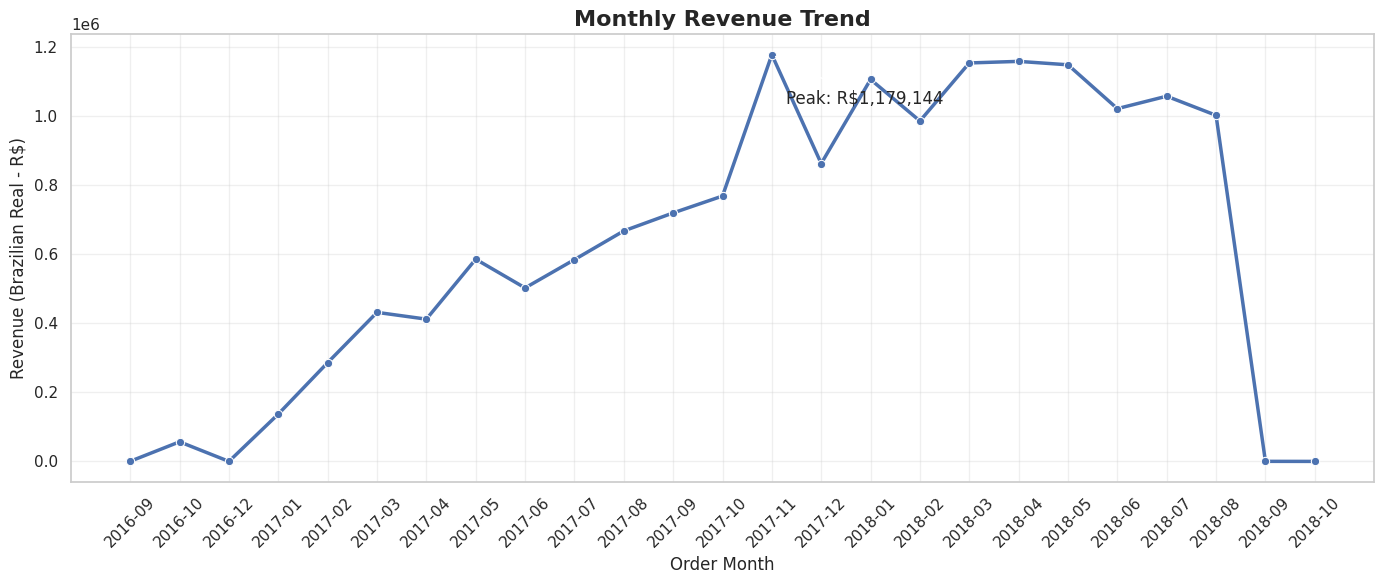

In [74]:
# ============================================================
# 38. CHART 1 - MONTHLY REVENUE TREND
# ============================================================

# Calculate monthly revenue
monthly_revenue = (
    eda_df.groupby("order_month")["total_order_value"]
    .sum()
    .reset_index()
)

# Create the chart
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x="order_month",
    y="total_order_value",
    marker="o",
    linewidth=2.5
)

plt.title("Monthly Revenue Trend", fontsize=16, fontweight="bold")
plt.xlabel("Order Month")
plt.ylabel("Revenue (Brazilian Real - R$)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
# Annotate the highest revenue month
peak = monthly_revenue.loc[
    monthly_revenue["total_order_value"].idxmax()
]

plt.annotate(
    f"Peak: R${peak['total_order_value']:,.0f}",
    xy=(peak["order_month"], peak["total_order_value"]),
    xytext=(10, -35),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)
plt.tight_layout()

plt.show()

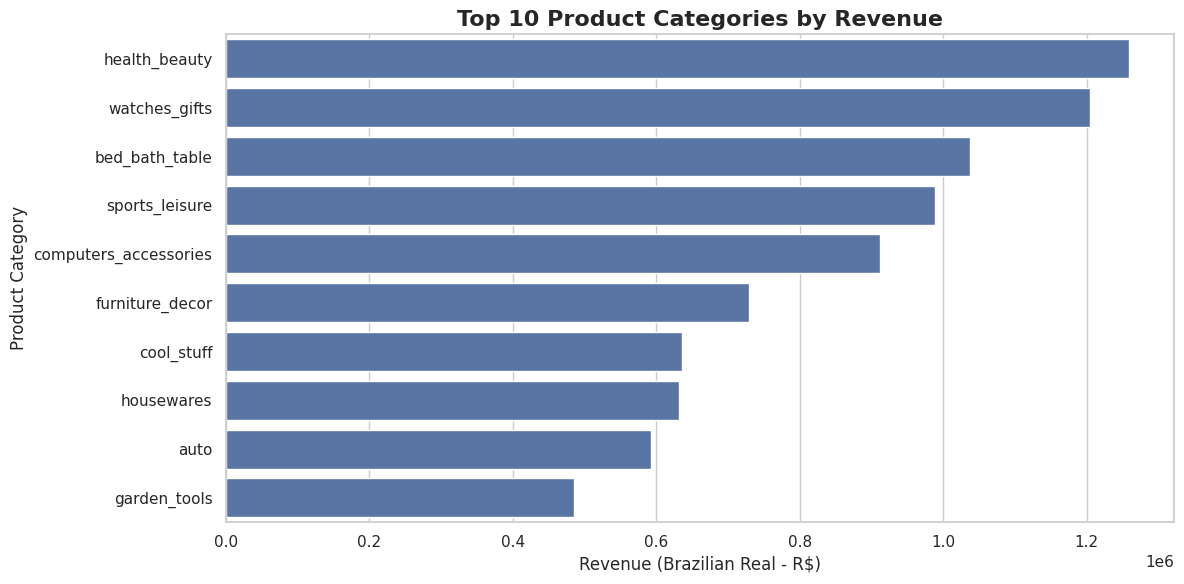

In [75]:
# ============================================================
# 39. CHART 2 - TOP 10 PRODUCT CATEGORIES BY REVENUE
# ============================================================

category_revenue = (
    clean_datasets["order_items"]
    .merge(
        clean_datasets["products"][
            ["product_id", "product_category_name"]
        ],
        on="product_id",
        how="left"
    )
    .groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_revenue,
    x="price",
    y="product_category_name"
)

plt.title("Top 10 Product Categories by Revenue",
          fontsize=16, fontweight="bold")
plt.xlabel("Revenue (Brazilian Real - R$)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

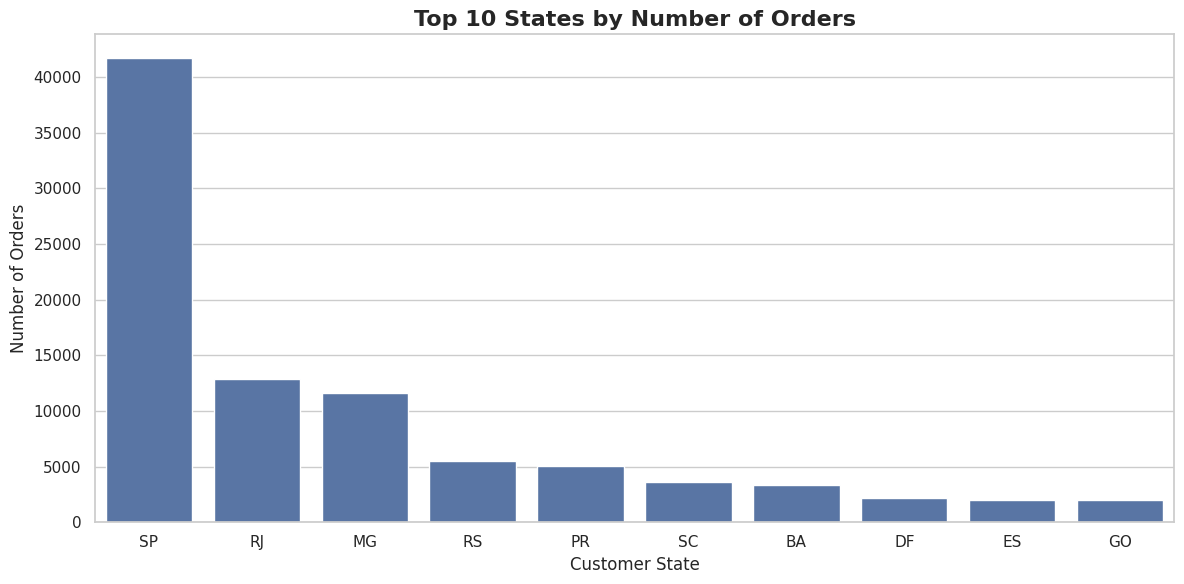

In [76]:
# ============================================================
# 40. CHART 3 - TOP 10 STATES BY NUMBER OF ORDERS
# ============================================================

state_orders = (
    eda_df.groupby("customer_state")["order_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="total_orders")
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=state_orders,
    x="customer_state",
    y="total_orders"
)

plt.title("Top 10 States by Number of Orders",
          fontsize=16, fontweight="bold")
plt.xlabel("Customer State")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

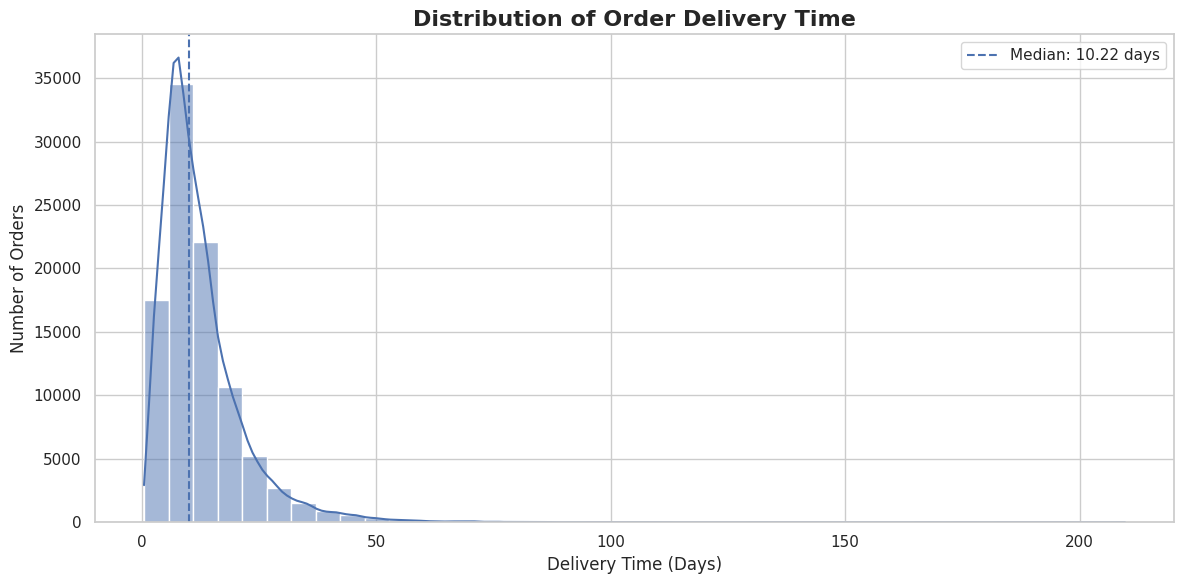

In [77]:
# ============================================================
# 41. CHART 4 - DELIVERY TIME DISTRIBUTION
# ============================================================

delivery_data = eda_df["delivery_days"].dropna()

plt.figure(figsize=(12, 6))

sns.histplot(
    delivery_data,
    bins=40,
    kde=True
)

plt.title("Distribution of Order Delivery Time",
          fontsize=16, fontweight="bold")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")

plt.axvline(
    delivery_data.median(),
    linestyle="--",
    label=f"Median: {delivery_data.median():.2f} days"
)

plt.legend()
plt.tight_layout()
plt.show()

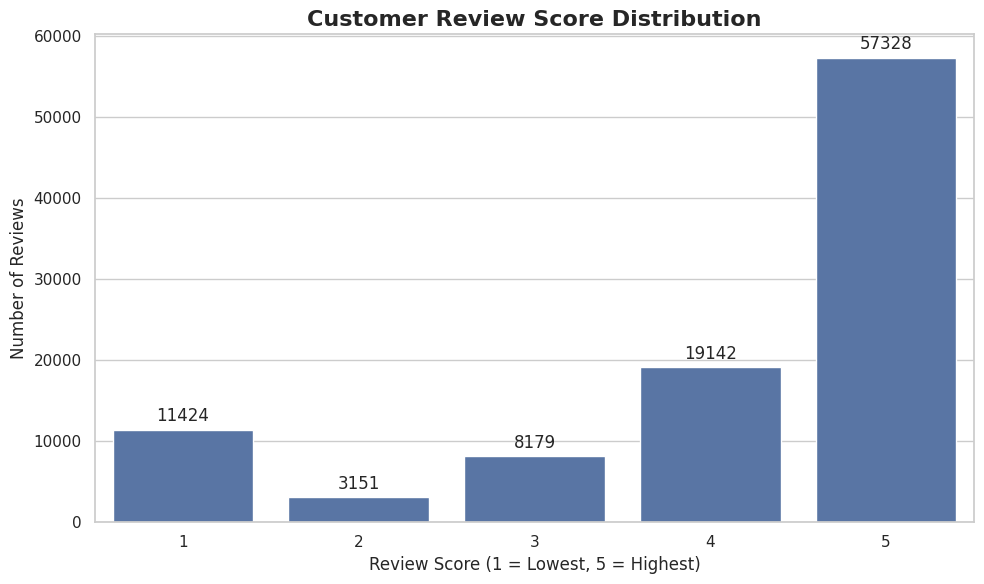

In [78]:

# ============================================================
# 42. CHART 5 - REVIEW SCORE DISTRIBUTION
# ============================================================

review_data = clean_datasets["order_reviews"]

review_counts = (
    review_data["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

review_counts.columns = ["review_score", "total_reviews"]

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=review_counts,
    x="review_score",
    y="total_reviews"
)

plt.title("Customer Review Score Distribution",
          fontsize=16, fontweight="bold")
plt.xlabel("Review Score (1 = Lowest, 5 = Highest)")
plt.ylabel("Number of Reviews")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

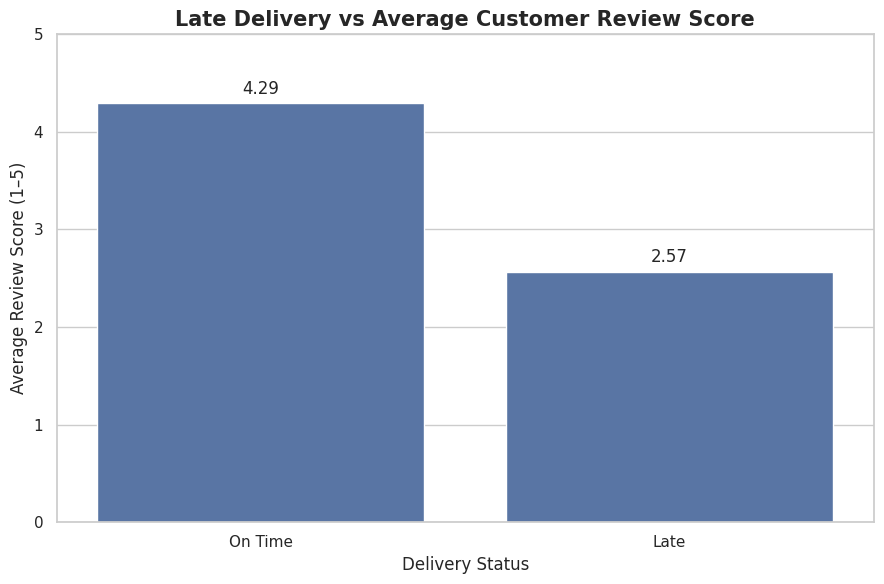

In [79]:
# ============================================================
# 43. CHART 6 - LATE DELIVERY VS REVIEW SCORE
# ============================================================

delivery_reviews = master_df.dropna(
    subset=["is_late", "review_score"]
).copy()

delivery_reviews["delivery_status"] = (
    delivery_reviews["is_late"]
    .map({True: "Late", False: "On Time"})
)

review_comparison = (
    delivery_reviews
    .groupby("delivery_status")["review_score"]
    .mean()
    .reindex(["On Time", "Late"])
    .reset_index()
)

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=review_comparison,
    x="delivery_status",
    y="review_score"
)

plt.title("Late Delivery vs Average Customer Review Score",
          fontsize=15, fontweight="bold")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score (1–5)")
plt.ylim(0, 5)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4)

plt.tight_layout()
plt.show()

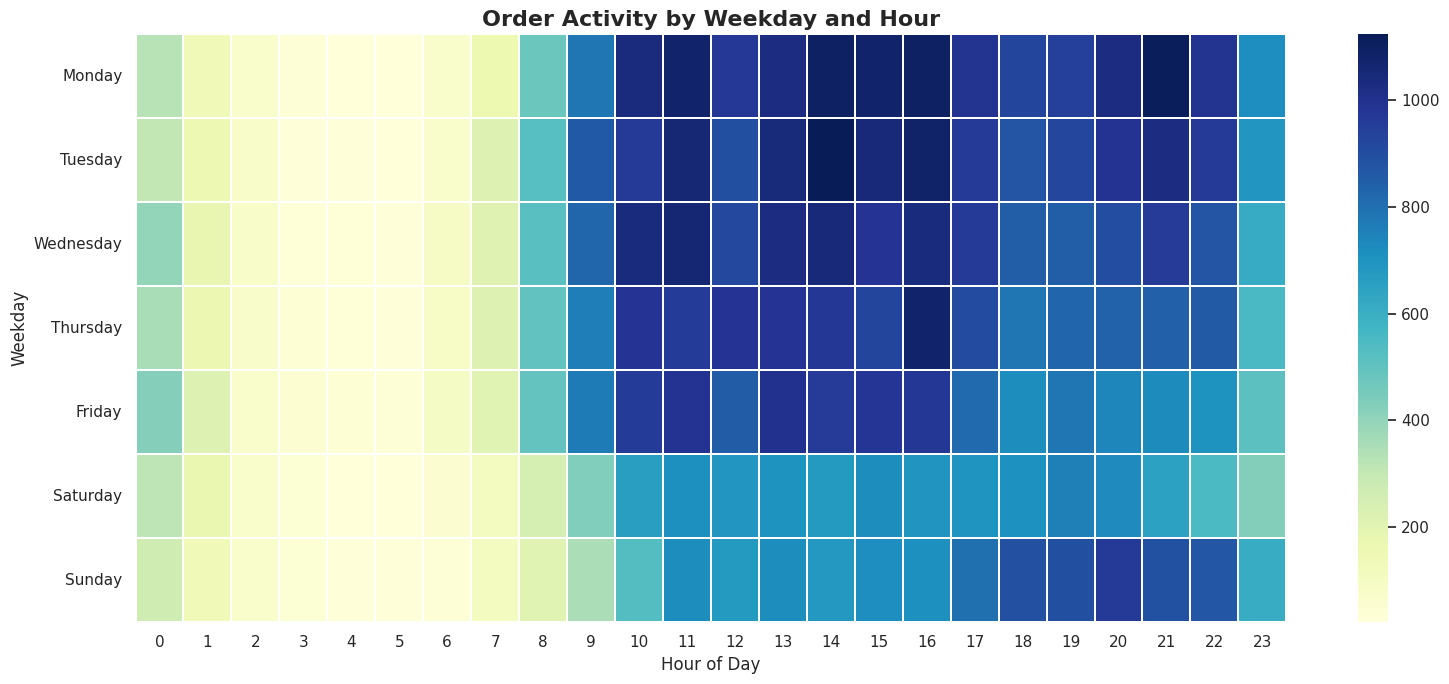

In [80]:
# ============================================================
# 44. CHART 7 - WEEKDAY AND HOUR ORDER HEATMAP
# ============================================================

heatmap_data = eda_df.pivot_table(
    index="order_weekday",
    columns="order_hour",
    values="order_id",
    aggfunc="nunique",
    fill_value=0
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

heatmap_data = heatmap_data.reindex(weekday_order)

plt.figure(figsize=(16, 7))

sns.heatmap(
    heatmap_data,
    cmap="YlGnBu",
    linewidths=0.3
)

plt.title("Order Activity by Weekday and Hour",
          fontsize=16, fontweight="bold")
plt.xlabel("Hour of Day")
plt.ylabel("Weekday")

plt.tight_layout()
plt.show()

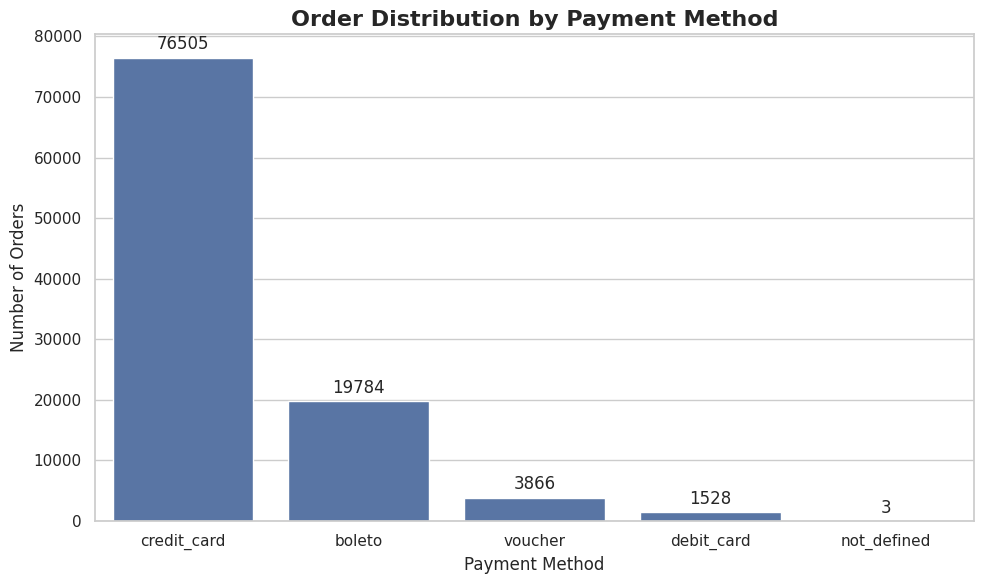

In [81]:
# ============================================================
# 45. CHART 8 - PAYMENT METHOD DISTRIBUTION
# ============================================================

payment_counts = (
    clean_datasets["order_payments"]
    .groupby("payment_type")["order_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="total_orders")
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=payment_counts,
    x="payment_type",
    y="total_orders"
)

plt.title("Order Distribution by Payment Method",
          fontsize=16, fontweight="bold")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

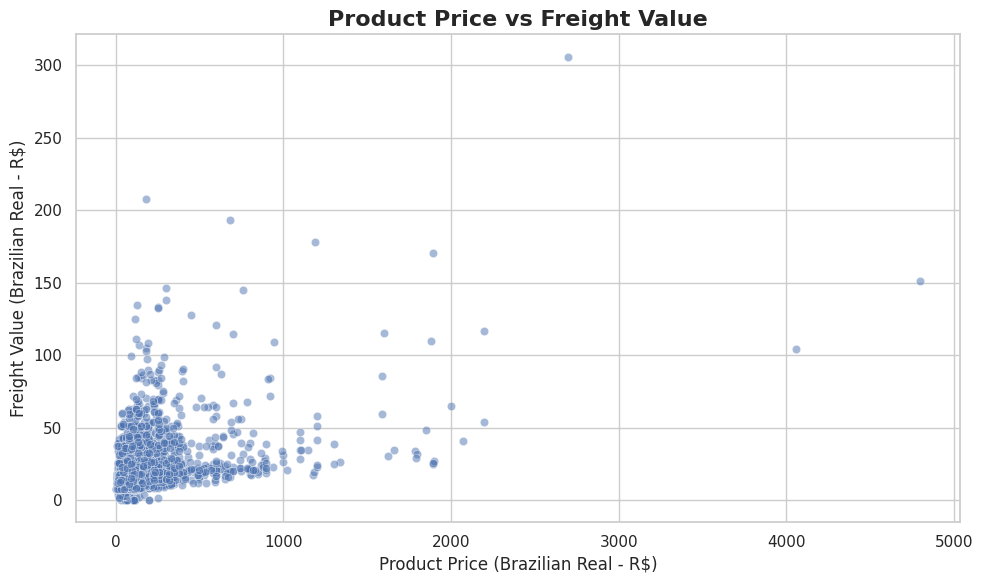

In [82]:
# ============================================================
# 46. CHART 9 - PRODUCT PRICE VS FREIGHT VALUE
# ============================================================

price_freight = clean_datasets["order_items"].sample(
    n=min(5000, len(clean_datasets["order_items"])),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=price_freight,
    x="price",
    y="freight_value",
    alpha=0.5
)

plt.title("Product Price vs Freight Value",
          fontsize=16, fontweight="bold")
plt.xlabel("Product Price (Brazilian Real - R$)")
plt.ylabel("Freight Value (Brazilian Real - R$)")

plt.tight_layout()
plt.show()

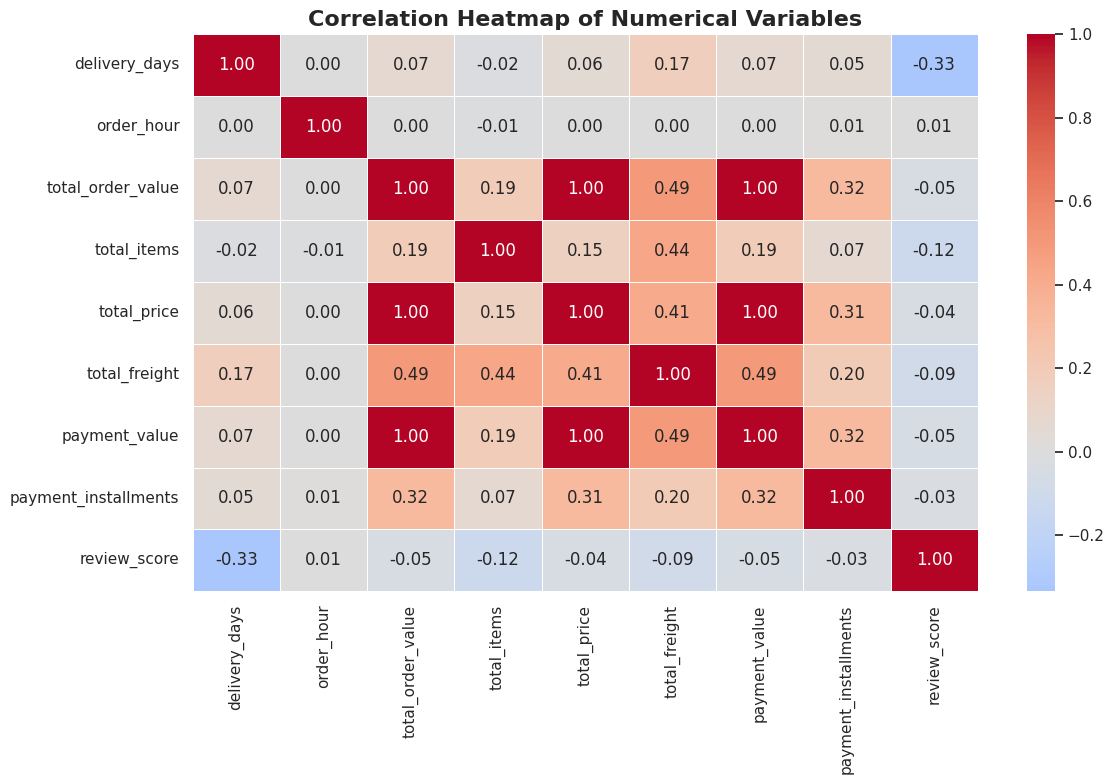

In [83]:
# ============================================================
# 47. CHART 10 - CORRELATION HEATMAP
# ============================================================

numeric_data = eda_df.select_dtypes(include="number")

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables",
          fontsize=16, fontweight="bold")

plt.tight_layout()
plt.show()

# 8. Customer Segmentation (RFM Analysis)

RFM analysis is used to understand customer purchasing behaviour through three metrics:

- Recency: How recently a customer placed an order.
- Frequency: How many orders a customer placed.
- Monetary: How much a customer spent.

These metrics will be used to identify valuable customer groups and support targeted marketing strategies.

In [84]:
# ============================================================
# 48. CREATE RFM TABLE
# ============================================================

# Set the analysis date based on the latest purchase date
analysis_date = (
    eda_df["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

# Calculate Recency, Frequency and Monetary for each customer
rfm = (
    eda_df.groupby("customer_id")
    .agg(
        Recency=(
            "order_purchase_timestamp",
            lambda x: (analysis_date - x.max()).days
        ),
        Frequency=("order_id", "nunique"),
        Monetary=("total_order_value", "sum")
    )
    .reset_index()
)

print("RFM table created successfully!")
print("RFM dataset shape:", rfm.shape)

display(rfm.head())

RFM table created successfully!
RFM dataset shape: (99441, 4)


,customer_id,Recency,Frequency,Monetary
0,00012a2ce6f8dcda20d059ce98491703,338,1,114.74
1,000161a058600d5901f007fab4c27140,459,1,67.41
2,0001fd6190edaaf884bcaf3d49edf079,597,1,195.42
3,0002414f95344307404f0ace7a26f1d5,428,1,179.35
4,000379cdec625522490c315e70c7a9fb,199,1,107.01


In [85]:
# ============================================================
# 49. SCALE RFM FEATURES
# ============================================================

from sklearn.preprocessing import StandardScaler

# Select RFM columns
rfm_features = rfm[["Recency", "Frequency", "Monetary"]]

# Standardize the features
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_features)

# Convert scaled values into a DataFrame
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"]
)

print("RFM features scaled successfully!")

display(rfm_scaled_df.head())


RFM features scaled successfully!


,Recency,Frequency,Monetary
0,0.31,0.00,-0.20
1,1.09,0.00,-0.42
2,1.99,0.00,0.16
3,0.89,0.00,0.09
4,-0.60,0.00,-0.24


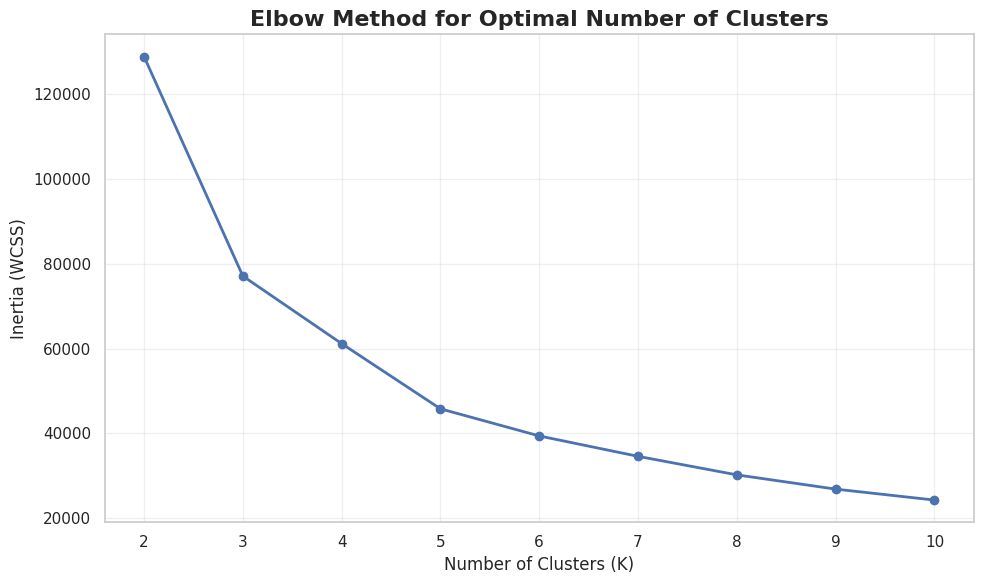

In [86]:
# ============================================================
# 50. ELBOW METHOD FOR OPTIMAL K
# ============================================================

from sklearn.cluster import KMeans

inertia_values = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled_df)

    inertia_values.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(10, 6))

plt.plot(
    k_values,
    inertia_values,
    marker="o",
    linewidth=2
)

plt.title("Elbow Method for Optimal Number of Clusters",
          fontsize=16, fontweight="bold")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [87]:
# ============================================================
# 51. APPLY KMEANS CLUSTERING
# ============================================================

# Create KMeans model with 5 clusters
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Assign cluster labels to customers
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled_df)

print("KMeans clustering completed successfully!")

print("\nNumber of customers in each cluster:")
display(rfm["Cluster"].value_counts().sort_index())

display(rfm.head())

KMeans clustering completed successfully!

Number of customers in each cluster:


,count
Cluster,
0,4780
1,35473
2,659
3,35655
4,22874


,customer_id,Recency,Frequency,Monetary,Cluster
0,00012a2ce6f8dcda20d059ce98491703,338,1,114.74,3
1,000161a058600d5901f007fab4c27140,459,1,67.41,4
2,0001fd6190edaaf884bcaf3d49edf079,597,1,195.42,4
3,0002414f95344307404f0ace7a26f1d5,428,1,179.35,4
4,000379cdec625522490c315e70c7a9fb,199,1,107.01,1


In [88]:
# ============================================================
# 52. CUSTOMER CLUSTER ANALYSIS
# ============================================================

cluster_summary = (
    rfm.groupby("Cluster")
    .agg(
        Total_Customers=("customer_id", "count"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary=("Monetary", "mean")
    )
    .round(2)
    .reset_index()
)

print("Customer Cluster Summary:")
display(cluster_summary)

Customer Cluster Summary:


,Cluster,Total_Customers,Average_Recency,Average_Frequency,Average_Monetary
0,0,4780,277.35,1.00,665.40
1,1,35473,136.83,1.00,123.71
2,2,659,291.34,1.00,"1,928.02"
3,3,35655,305.58,1.00,117.07
4,4,22874,509.77,1.00,123.71


In [89]:
# ============================================================
# 53. NAME CUSTOMER SEGMENTS
# ============================================================

segment_names = {
    0: "High-Value Customers",
    1: "Recent Low-Spend Customers",
    2: "Premium High-Spend Customers",
    3: "At-Risk Customers",
    4: "Lost Customers"
}

rfm["Customer_Segment"] = rfm["Cluster"].map(segment_names)

print("Customer segments assigned successfully!")

display(
    rfm.groupby("Customer_Segment")
    .agg(
        Total_Customers=("customer_id", "count"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary=("Monetary", "mean")
    )
    .round(2)
    .reset_index()
)

Customer segments assigned successfully!


,Customer_Segment,Total_Customers,Average_Recency,Average_Frequency,Average_Monetary
0,At-Risk Customers,35655,305.58,1.00,117.07
1,High-Value Customers,4780,277.35,1.00,665.40
2,Lost Customers,22874,509.77,1.00,123.71
3,Premium High-Spend Customers,659,291.34,1.00,"1,928.02"
4,Recent Low-Spend Customers,35473,136.83,1.00,123.71


# 9. Interactive Business Dashboard

This section presents the key business performance indicators and interactive visualizations of the Olist E-Commerce business.

The dashboard will include revenue, orders, average order value, customer reviews, delivery performance and customer segmentation.

In [90]:
# ============================================================
# 55. CALCULATE DASHBOARD KPIs
# ============================================================

# Total revenue
total_revenue = eda_df["total_order_value"].sum()

# Total unique orders
total_orders = eda_df["order_id"].nunique()

# Average order value
average_order_value = eda_df["total_order_value"].mean()

# Average customer review score
average_review_score = eda_df["review_score"].mean()

# Late delivery percentage
late_delivery_percentage = (
    eda_df["is_late"].mean() * 100
)

print("DASHBOARD KPI SUMMARY")
print("------------------------------")
print(f"Total Revenue: R${total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value: R${average_order_value:,.2f}")
print(f"Average Review Score: {average_review_score:.2f}/5")
print(f"Late Delivery: {late_delivery_percentage:.2f}%")

DASHBOARD KPI SUMMARY
------------------------------
Total Revenue: R$15,843,553.24
Total Orders: 99,441
Average Order Value: R$160.58
Average Review Score: 4.09/5
Late Delivery: 8.11%


In [91]:
# ============================================================
# 56. PLOTLY DASHBOARD SETUP
# ============================================================

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Set a consistent dark dashboard theme
px.defaults.template = "plotly_dark"

print("Plotly dashboard environment ready!")

Plotly dashboard environment ready!


In [110]:

# ============================================================
# 57. DASHBOARD CHART 1 - MONTHLY REVENUE TREND
# ============================================================

monthly_revenue = (
    eda_df.groupby("order_month")["total_order_value"]
    .sum()
    .reset_index()
    .sort_values("order_month")
)

fig_revenue = px.area(
    monthly_revenue,
    x="order_month",
    y="total_order_value",
    title="Monthly Revenue Trend",
    labels={
        "order_month": "Month",
        "total_order_value": "Revenue (R$)"
    },
    color_discrete_sequence=["#38BDF8"],
    template="plotly_dark"
)

fig_revenue.update_traces(
    line=dict(width=2.5),
    fillcolor="rgba(56, 189, 248, 0.15)",
    hovertemplate="Month: %{x}<br>Revenue: R$ %{y:,.2f}<extra></extra>"
)

fig_revenue.update_layout(
    height=400,
    title_x=0.03,
    hovermode="x unified",
    paper_bgcolor="#111827",
    plot_bgcolor="#111827",
    font=dict(color="#E5E7EB"),
    margin=dict(l=50, r=30, t=65, b=50)
)

fig_revenue.show()


In [115]:

# ============================================================
# 58. DASHBOARD CHART 2 - CATEGORY REVENUE
# ============================================================

fig2 = px.bar(
    category_revenue.sort_values("price", ascending=True),
    x="price",
    y="product_category_name",
    orientation="h",
    title="Top 10 Product Categories by Revenue",
    labels={
        "price": "Revenue (R$)",
        "product_category_name": "Product Category"
    },
    template="plotly_dark"
)

fig2.update_traces(
    marker=dict(
        color="rgba(96, 165, 250, 0.30)",
        line=dict(
            color="#60A5FA",
            width=1.2
        )
    ),
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Revenue: R$ %{x:,.2f}"
        "<extra></extra>"
    )
)

fig2.update_layout(
    height=430,
    title_x=0.03,
    paper_bgcolor="#111827",
    plot_bgcolor="#111827",
    font=dict(
        family="Arial",
        size=12,
        color="#E5E7EB"
    ),
    margin=dict(l=150, r=30, t=65, b=50),
    xaxis=dict(
        title="Revenue (R$)",
        gridcolor="#263449",
        zeroline=False
    ),
    yaxis=dict(
        title="",
        showgrid=False
    )
)

fig2.show()


In [116]:

# ============================================================
# 59. DASHBOARD CHART 3 - ORDERS BY STATE
# ============================================================

state_orders = (
    eda_df.groupby("customer_state")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
    .sort_values("total_orders", ascending=False)
)

fig3 = px.bar(
    state_orders.head(10).sort_values("total_orders"),
    x="total_orders",
    y="customer_state",
    orientation="h",
    title="Top 10 Brazilian States by Orders",
    labels={
        "customer_state": "State",
        "total_orders": "Number of Orders"
    },
    template="plotly_dark"
)

fig3.update_traces(
    marker=dict(
        color="rgba(96, 165, 250, 0.30)",
        line=dict(color="#60A5FA", width=1.2)
    ),
    hovertemplate=(
        "<b>State: %{y}</b><br>"
        "Orders: %{x:,}"
        "<extra></extra>"
    )
)

fig3.update_layout(
    height=430,
    title_x=0.03,
    paper_bgcolor="#111827",
    plot_bgcolor="#111827",
    font=dict(
        family="Arial",
        size=12,
        color="#E5E7EB"
    ),
    margin=dict(l=70, r=30, t=65, b=50),
    xaxis=dict(
        title="Number of Orders",
        gridcolor="#263449",
        zeroline=False
    ),
    yaxis=dict(
        title="",
        showgrid=False
    )
)

fig3.show()


In [123]:

# ============================================================
# 60. DASHBOARD CHART 4 - DELIVERY VS REVIEW SCORE
# ============================================================

delivery_review = (
    eda_df.groupby("is_late")["review_score"]
    .mean()
    .reset_index()
)

delivery_review["Delivery Status"] = (
    delivery_review["is_late"]
    .map({False: "On Time", True: "Late"})
)

fig4 = px.bar(
    delivery_review,
    x="Delivery Status",
    y="review_score",
    color="Delivery Status",
    color_discrete_map={
        "On Time": "#38BDF8",
        "Late": "#FB923C"
    },
    title="Customer Satisfaction: On-Time vs Late Delivery",
    labels={
        "review_score": "Average Review Score"
    },
    template="plotly_dark"
)

fig4.update_traces(
    marker=dict(
        opacity=0.85,
        line=dict(width=1, color="rgba(255,255,255,0.4)")
    ),
    texttemplate="%{y:.2f}",
    textposition="outside",
    hovertemplate=(
        "Delivery: %{x}<br>"
        "Average Review: %{y:.2f}/5"
        "<extra></extra>"
    )
)

fig4.update_layout(
    height=450,
    showlegend=False,
    title_x=0.03,
    yaxis=dict(
        title="Average Review Score",
        range=[0, 5],
        gridcolor="#263449",
        zeroline=False
    ),
    xaxis=dict(title="Delivery Status", showgrid=False),
    paper_bgcolor="#111827",
    plot_bgcolor="#111827",
    font=dict(family="Arial", size=12, color="#E5E7EB"),
    margin=dict(l=55, r=30, t=70, b=50)
)

fig4.show()


In [124]:

# ============================================================
# 61. DASHBOARD CHART 5 - PAYMENT METHOD DISTRIBUTION
# ============================================================

payment_summary = (
    clean_datasets["order_payments"]
    .groupby("payment_type")["payment_value"]
    .sum()
    .reset_index()
    .sort_values("payment_value", ascending=False)
)

fig5 = px.pie(
    payment_summary,
    names="payment_type",
    values="payment_value",
    hole=0.55,
    title="Revenue Distribution by Payment Method",
    template="plotly_dark",
    color_discrete_sequence=[
        "#38BDF8",
        "#818CF8",
        "#F59E0B",
        "#34D399",
        "#F472B6"
    ]
)

fig5.update_traces(
    textposition="inside",
    textinfo="percent+label",
    marker=dict(
        line=dict(color="#111827", width=3)
    ),
    hovertemplate=(
        "Payment: %{label}<br>"
        "Value: R$ %{value:,.2f}<br>"
        "Share: %{percent}"
        "<extra></extra>"
    )
)

fig5.update_layout(
    height=450,
    title_x=0.03,
    paper_bgcolor="#111827",
    plot_bgcolor="#111827",
    font=dict(
        family="Arial",
        size=12,
        color="#E5E7EB"
    ),
    margin=dict(l=30, r=30, t=65, b=30),
    showlegend=True,
    legend=dict(
        orientation="h",
        y=-0.08,
        x=0.5,
        xanchor="center"
    )
)

fig5.show()


In [127]:

# ============================================================
# 62. DASHBOARD CHART 6 - CUSTOMER SEGMENTS
# ============================================================

segment_summary = (
    rfm.groupby("Customer_Segment")
    .size()
    .reset_index(name="Total_Customers")
    .sort_values("Total_Customers", ascending=False)
)

fig6 = px.bar(
    segment_summary,
    x="Customer_Segment",
    y="Total_Customers",
    color="Customer_Segment",
    title="Customer Distribution by RFM Segment",
    labels={
        "Customer_Segment": "Customer Segment",
        "Total_Customers": "Number of Customers"
    },
    template="plotly_dark",
    color_discrete_sequence=[
        "#38BDF8",
        "#818CF8",
        "#F59E0B",
        "#34D399",
        "#F472B6"
    ]
)

fig6.update_traces(
    marker=dict(
        opacity=0.85,
        line=dict(
            color="rgba(255,255,255,0.35)",
            width=1
        )
    ),
    texttemplate="%{y:,}",
    textposition="outside",
    hovertemplate=(
        "Segment: %{x}<br>"
        "Customers: %{y:,}"
        "<extra></extra>"
    )
)

fig6.update_layout(
    height=450,
    title_x=0.03,
    showlegend=False,
    xaxis=dict(
        title="Customer Segment",
        tickangle=-20,
        showgrid=False
    ),
    yaxis=dict(
        title="Number of Customers",
        gridcolor="#263449",
        zeroline=False
    ),
    paper_bgcolor="#111827",
    plot_bgcolor="#111827",
    font=dict(
        family="Arial",
        size=12,
        color="#E5E7EB"
    ),
    margin=dict(l=55, r=30, t=70, b=80)
)

fig6.show()



In [157]:

# ============================================================
# 63. OLIST EXECUTIVE INTELLIGENCE DASHBOARD
# Premium Enterprise Business Intelligence Design
# ============================================================

import os

# ------------------------------------------------------------
# 1. CREATE DASHBOARD DIRECTORY
# ------------------------------------------------------------

os.makedirs("/content/dashboard", exist_ok=True)

# ------------------------------------------------------------
# 2. COLLECT SIX EXISTING CHARTS
# ------------------------------------------------------------

figures = [
    fig_revenue,
    fig2,
    fig3,
    fig4,
    fig5,
    fig6
]

# ------------------------------------------------------------
# 3. APPLY CONSISTENT CHART STYLING
# ------------------------------------------------------------

for fig in figures:

    fig.update_layout(
        template="plotly_dark",
        paper_bgcolor="rgba(0,0,0,0)",
        plot_bgcolor="rgba(0,0,0,0)",

        font=dict(
            family="Inter, Arial, sans-serif",
            size=11,
            color="#AAB6D3"
        ),

        title=dict(
            font=dict(
                size=15,
                color="#F4F6FF"
            ),
            x=0.03,
            xanchor="left"
        ),

        height=280,

        margin=dict(
            l=42,
            r=20,
            t=55,
            b=40
        ),

        hoverlabel=dict(
            bgcolor="#151D32",
            bordercolor="#48DED3",
            font_size=12,
            font_color="#FFFFFF"
        ),

        xaxis=dict(
            gridcolor="rgba(148,163,184,0.09)",
            zerolinecolor="rgba(148,163,184,0.12)"
        ),

        yaxis=dict(
            gridcolor="rgba(148,163,184,0.09)",
            zerolinecolor="rgba(148,163,184,0.12)"
        ),

        legend=dict(
            bgcolor="rgba(0,0,0,0)",
            font=dict(
                color="#AAB6D3",
                size=10
            )
        )
    )

# Payment donut chart styling
fig5.update_traces(
    textposition="inside",
    textinfo="percent",
    insidetextfont=dict(
        size=11,
        color="#FFFFFF"
    )
)

# ------------------------------------------------------------
# 4. CREATE KPI DATA
# ------------------------------------------------------------

kpis = [
    {
        "label": "TOTAL REVENUE",
        "value": f"R$ {total_revenue:,.2f}",
        "description": "Total sales generated",
        "accent": "cyan",
        "icon": "↗"
    },
    {
        "label": "TOTAL ORDERS",
        "value": f"{total_orders:,}",
        "description": "Unique customer orders",
        "accent": "purple",
        "icon": "▦"
    },
    {
        "label": "AVERAGE ORDER VALUE",
        "value": f"R$ {average_order_value:,.2f}",
        "description": "Revenue per order",
        "accent": "blue",
        "icon": "◈"
    },
    {
        "label": "AVERAGE REVIEW",
        "value": f"{average_review_score:.2f} / 5",
        "description": "Customer satisfaction",
        "accent": "pink",
        "icon": "★"
    },
    {
        "label": "LATE DELIVERY RATE",
        "value": f"{late_delivery_percentage:.2f}%",
        "description": "Orders delivered late",
        "accent": "orange",
        "icon": "◷"
    }
]

# ------------------------------------------------------------
# 5. GENERATE KPI HTML
# ------------------------------------------------------------

kpi_html = ""

for kpi in kpis:

    kpi_html += f"""
    <div class="kpi-card {kpi['accent']}">

        <div class="kpi-header">

            <span class="kpi-label">
                {kpi['label']}
            </span>

            <span class="kpi-icon">
                {kpi['icon']}
            </span>

        </div>

        <div class="kpi-value">
            {kpi['value']}
        </div>

        <div class="kpi-description">
            {kpi['description']}
        </div>

    </div>
    """

# ------------------------------------------------------------
# 6. CONVERT PLOTLY CHARTS INTO HTML
# ------------------------------------------------------------

chart_html = []

for index, fig in enumerate(figures):

    chart_html.append(
        fig.to_html(
            full_html=False,

            include_plotlyjs=(
                "cdn" if index == 0 else False
            ),

            config={
                "responsive": True,
                "displaylogo": False,
                "scrollZoom": False,
                "modeBarButtonsToRemove": [
                    "lasso2d",
                    "select2d"
                ]
            }
        )
    )

# ------------------------------------------------------------
# 7. BUILD DASHBOARD HTML
# ------------------------------------------------------------

dashboard_html = f"""
<!DOCTYPE html>
<html lang="en">

<head>

<meta charset="UTF-8">

<meta name="viewport"
content="width=device-width, initial-scale=1.0">

<title>OLIST | Executive Intelligence</title>

<link rel="preconnect" href="https://fonts.googleapis.com">

<link href="https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500;600;700;800&family=Space+Grotesk:wght@500;600;700&display=swap"
rel="stylesheet">

<style>

/* =========================================================
   GLOBAL DESIGN SYSTEM
========================================================= */

:root {{

    --background: #080C18;
    --sidebar: #0C1120;

    --cyan: #48DED3;
    --purple: #9B8AFF;
    --blue: #66A9FF;
    --pink: #F18DBA;
    --orange: #FFB86C;

    --text: #F5F7FF;
    --muted: #8996B3;

    --border: rgba(151,172,220,0.15);

}}

* {{
    margin: 0;
    padding: 0;
    box-sizing: border-box;
}}

html {{
    scroll-behavior: smooth;
}}

body {{

    background:
        radial-gradient(
            ellipse at 75% 0%,
            rgba(104,83,255,0.14),
            transparent 38%
        ),
        radial-gradient(
            ellipse at 10% 80%,
            rgba(32,193,190,0.07),
            transparent 35%
        ),
        var(--background);

    color: var(--text);

    font-family: 'DM Sans', sans-serif;

    min-height: 100vh;

}}

/* =========================================================
   APPLICATION LAYOUT
========================================================= */

.app {{
    display: flex;
    min-height: 100vh;
}}

.sidebar {{

    width: 210px;
    flex-shrink: 0;

    background: rgba(10,15,30,0.93);

    border-right: 1px solid var(--border);

    padding: 26px 16px;

    display: flex;
    flex-direction: column;

    backdrop-filter: blur(20px);

}}

.brand {{

    display: flex;
    align-items: center;
    gap: 11px;

    margin-bottom: 43px;
    padding: 0 8px;

}}

.brand-icon {{

    width: 38px;
    height: 38px;

    display: grid;
    place-items: center;

    border-radius: 12px;

    background:
        linear-gradient(135deg,#7566F6,#35D6CC);

    box-shadow:
        0 0 22px rgba(113,100,246,0.35);

    font-family: 'Space Grotesk',sans-serif;
    font-size: 20px;
    font-weight: 700;

}}

.brand-name {{

    font-family: 'Space Grotesk',sans-serif;
    font-size: 17px;
    font-weight: 700;

}}

.brand-name span {{
    color: var(--cyan);
}}

.nav-heading {{

    color: #5E6A87;

    font-size: 9px;
    font-weight: 700;
    letter-spacing: 1.8px;

    padding: 0 12px;
    margin-bottom: 13px;

}}

.nav-item {{

    display: flex;
    align-items: center;
    gap: 12px;

    padding: 12px;

    margin-bottom: 6px;

    border-radius: 10px;

    text-decoration: none;

    color: #929DB9;

    font-size: 12px;

    transition: 0.2s ease;

}}

.nav-item:hover,
.nav-item.active {{

    color: #D3CEFF;

    background:
        linear-gradient(
            100deg,
            rgba(140,122,255,0.19),
            rgba(140,122,255,0.04)
        );

    border: 1px solid rgba(155,138,255,0.18);

}}

.nav-icon {{
    width: 19px;
    text-align: center;
    font-size: 15px;
}}

.sidebar-footer {{

    margin-top: auto;

    border-top: 1px solid var(--border);

    padding: 18px 10px 0;

    color: #707D9A;

    font-size: 9px;
    line-height: 1.9;
    letter-spacing: 0.6px;

}}

/* =========================================================
   MAIN CONTENT
========================================================= */

.main {{

    flex: 1;
    min-width: 0;

    padding: 25px 29px;

}}

.topbar {{

    display: flex;
    align-items: center;
    justify-content: space-between;

    margin-bottom: 26px;
    gap: 12px;

}}

.breadcrumb {{
    color: var(--muted);
    font-size: 11px;
}}

.breadcrumb strong {{
    color: #DCE2F5;
}}

.status {{

    display: flex;
    align-items: center;
    gap: 8px;

    padding: 7px 12px;

    background: rgba(25,37,61,0.65);

    border: 1px solid var(--border);

    border-radius: 30px;

    color: #B3C0D9;
    font-size: 10px;

}}

.status-dot {{

    height: 7px;
    width: 7px;

    border-radius: 50%;

    background: var(--cyan);

    box-shadow: 0 0 12px var(--cyan);

}}

/* =========================================================
   HEADER
========================================================= */

.heading {{
    margin-bottom: 21px;
}}

.eyebrow {{

    color: var(--cyan);

    font-size: 9px;
    font-weight: 700;
    letter-spacing: 2px;

    margin-bottom: 8px;

}}

.heading h1 {{

    font-family: 'Space Grotesk',sans-serif;

    font-size: clamp(25px,2.5vw,34px);

    font-weight: 700;
    letter-spacing: -1px;

}}

.heading p {{

    color: var(--muted);

    font-size: 11px;
    line-height: 1.7;

    margin-top: 7px;

}}

/* =========================================================
   SECTION HEADINGS
========================================================= */

.section-heading {{

    display: flex;
    align-items: center;
    justify-content: space-between;

    margin: 21px 0 12px;

}}

.section-heading h2 {{

    font-family: 'Space Grotesk',sans-serif;
    font-size: 13px;
    font-weight: 600;

}}

.section-caption {{

    color: #75819D;
    font-size: 9px;
    letter-spacing: 1px;

}}

/* =========================================================
   KPI CARDS
========================================================= */

.kpi-grid {{

    display: grid;

    grid-template-columns:
        repeat(5,minmax(0,1fr));

    gap: 12px;

}}

.kpi-card {{

    position: relative;
    overflow: hidden;

    min-width: 0;

    padding: 15px 14px;

    border-radius: 12px;

    border: 1px solid var(--border);

    background:
        linear-gradient(
            145deg,
            rgba(29,41,69,0.85),
            rgba(15,23,42,0.80)
        );

    backdrop-filter: blur(18px);

    box-shadow:
        0 10px 25px rgba(0,0,0,0.23),
        inset 0 1px 0 rgba(255,255,255,0.05);

    transition: 0.25s ease;

}}

.kpi-card:hover {{

    transform: translateY(-4px);

    border-color: rgba(72,222,211,0.45);

    box-shadow:
        0 15px 30px rgba(0,0,0,0.3),
        0 0 18px rgba(72,222,211,0.08);

}}

.kpi-header {{

    display: flex;
    align-items: center;
    justify-content: space-between;

    margin-bottom: 14px;

}}

.kpi-label {{

    color: #A2AEC9;

    font-size: 8px;
    font-weight: 700;
    letter-spacing: 0.7px;

}}

.kpi-icon {{
    color: var(--cyan);
    font-size: 14px;
}}

.purple .kpi-icon {{ color: var(--purple); }}
.blue .kpi-icon {{ color: var(--blue); }}
.pink .kpi-icon {{ color: var(--pink); }}
.orange .kpi-icon {{ color: var(--orange); }}

.kpi-value {{

    position: relative;
    z-index: 2;

    font-family: 'Space Grotesk',sans-serif;

    font-size: clamp(13px,1.3vw,20px);

    font-weight: 700;

    white-space: nowrap;
    letter-spacing: -0.4px;

}}

.kpi-description {{

    position: relative;
    z-index: 2;

    color: #7885A3;
    font-size: 9px;

    margin-top: 7px;

}}

.kpi-card::after {{

    content: "";

    position: absolute;

    width: 75px;
    height: 75px;

    border-radius: 50%;

    top: -48px;
    right: -30px;

    background: var(--cyan);

    filter: blur(36px);
    opacity: 0.22;

}}

.purple::after {{ background: var(--purple); }}
.blue::after {{ background: var(--blue); }}
.pink::after {{ background: var(--pink); }}
.orange::after {{ background: var(--orange); }}

/* =========================================================
   CHART GRID - ALL SIX EQUAL SIZE
========================================================= */

.chart-grid {{

    display: grid;

    grid-template-columns:
        repeat(2,minmax(0,1fr));

    grid-template-rows:
        repeat(3,300px);

    gap: 14px;

    align-items: stretch;

}}

.chart-card {{

    height: 300px;

    min-width: 0;
    min-height: 0;

    overflow: hidden;

    border-radius: 13px;

    border: 1px solid rgba(151,172,220,0.16);

    background:
        linear-gradient(
            145deg,
            rgba(23,34,59,0.88),
            rgba(13,20,37,0.94)
        );

    backdrop-filter: blur(18px);

    box-shadow:
        0 10px 25px rgba(0,0,0,0.22),
        inset 0 1px 0 rgba(255,255,255,0.04);

    transition:
        border-color 0.25s,
        transform 0.25s;

}}

.chart-card:hover {{

    border-color: rgba(72,222,211,0.35);

    transform: translateY(-2px);

}}

.chart-card .plotly-graph-div {{

    width: 100% !important;
    height: 100% !important;

}}

/* =========================================================
   FOOTER
========================================================= */

.footer {{

    margin-top: 25px;

    padding: 16px 0;

    border-top: 1px solid var(--border);

    display: flex;
    justify-content: space-between;
    align-items: center;

    gap: 12px;

    color: #75819B;
    font-size: 10px;

}}

.footer strong {{
    color: var(--cyan);
    letter-spacing: 1px;
}}

/* =========================================================
   RESPONSIVE
========================================================= */

@media(max-width:1200px) {{

    .sidebar {{
        width: 185px;
    }}

    .main {{
        padding: 22px 19px;
    }}

    .kpi-grid {{
        grid-template-columns: repeat(3,minmax(0,1fr));
    }}

    .chart-grid {{
        grid-template-rows: repeat(3,290px);
    }}

    .chart-card {{
        height: 290px;
    }}

}}

@media(max-width:850px) {{

    .sidebar {{
        width: 65px;
        padding: 22px 8px;
    }}

    .brand {{
        justify-content: center;
        padding: 0;
    }}

    .brand-name,
    .nav-heading,
    .nav-text,
    .sidebar-footer {{
        display: none;
    }}

    .nav-item {{
        justify-content: center;
        padding: 13px 5px;
    }}

}}

@media(max-width:650px) {{

    .chart-grid {{
        grid-template-columns: 1fr;
        grid-template-rows: none;
    }}

    .chart-card {{
        height: 280px;
    }}

    .kpi-grid {{
        grid-template-columns: repeat(2,minmax(0,1fr));
    }}

    .main {{
        padding: 18px 12px;
    }}

    .section-caption {{
        display: none;
    }}

    .footer {{
        flex-direction: column;
        align-items: flex-start;
    }}

}}

@media(max-width:400px) {{

    .kpi-grid {{
        grid-template-columns: 1fr;
    }}

}}

</style>

</head>

<body>

<div class="app">

    <!-- SIDEBAR -->

    <aside class="sidebar">

        <div class="brand">

            <div class="brand-icon">O</div>

            <div class="brand-name">
                OLIST<span>.</span>
            </div>

        </div>

        <div class="nav-heading">
            WORKSPACE
        </div>

        <a href="#overview" class="nav-item active">
            <span class="nav-icon">◈</span>
            <span class="nav-text">Executive Overview</span>
        </a>

        <a href="#performance" class="nav-item">
            <span class="nav-icon">▥</span>
            <span class="nav-text">Performance</span>
        </a>

        <a href="#analytics" class="nav-item">
            <span class="nav-icon">⌁</span>
            <span class="nav-text">Sales Analytics</span>
        </a>

        <a href="#analytics" class="nav-item">
            <span class="nav-icon">◎</span>
            <span class="nav-text">Customer Insights</span>
        </a>

        <div class="sidebar-footer">

            BUSINESS INTELLIGENCE

            <br>

            E-COMMERCE ANALYTICS

            <br>

            <span style="color:#48DED3;">
                OLIST PROJECT
            </span>

        </div>

    </aside>

    <!-- MAIN DASHBOARD -->

    <main class="main">

        <div class="topbar">

            <div class="breadcrumb">
                Workspace / <strong>Executive Overview</strong>
            </div>

            <div class="status">
                <span class="status-dot"></span>
                Analytics Dashboard
            </div>

        </div>

        <!-- HEADER -->

        <header class="heading" id="overview">

            <div class="eyebrow">
                OLIST / BUSINESS INTELLIGENCE
            </div>

            <h1>
                Executive Intelligence
            </h1>

            <p>
                A consolidated view of sales performance,
                delivery operations and customer experience.
            </p>

        </header>

        <!-- KPI SECTION -->

        <section id="performance">

            <div class="section-heading">

                <h2>Business Performance</h2>

                <span class="section-caption">
                    EXECUTIVE KPI OVERVIEW
                </span>

            </div>

            <div class="kpi-grid">

                {kpi_html}

            </div>

        </section>

        <!-- ANALYTICS SECTION -->

        <section id="analytics">

            <div class="section-heading">

                <h2>Business Analytics</h2>

                <span class="section-caption">
                    INTERACTIVE DATA EXPLORATION
                </span>

            </div>

            <div class="chart-grid">

                <div class="chart-card">
                    {chart_html[0]}
                </div>

                <div class="chart-card">
                    {chart_html[1]}
                </div>

                <div class="chart-card">
                    {chart_html[2]}
                </div>

                <div class="chart-card">
                    {chart_html[3]}
                </div>

                <div class="chart-card">
                    {chart_html[4]}
                </div>

                <div class="chart-card">
                    {chart_html[5]}
                </div>

            </div>

        </section>

        <!-- FOOTER -->

        <footer class="footer">

            <div>
                <strong>OLIST / INSIGHTS</strong>
                <br>
                Executive Analytics Portfolio
            </div>

            <div>
                Python · Pandas · Plotly
            </div>

        </footer>

    </main>

</div>

</body>

</html>
"""

# ------------------------------------------------------------
# 8. SAVE FINAL DASHBOARD
# ------------------------------------------------------------

dashboard_path = "/content/dashboard/dashboard.html"

with open(
    dashboard_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(dashboard_html)

# ------------------------------------------------------------
# 9. DISPLAY BUILD SUMMARY
# ------------------------------------------------------------

file_size = os.path.getsize(dashboard_path) / 1024

print("=" * 60)
print("OLIST EXECUTIVE INTELLIGENCE DASHBOARD")
print("=" * 60)

print(f"Dashboard file     : {dashboard_path}")
print(f"Interactive charts : {len(figures)}")
print(f"KPI cards          : {len(kpis)}")
print(f"File size          : {file_size:.2f} KB")
print("Theme              : Dark 3D Glassmorphism")
print("Accents            : Cyan / Purple / Teal")
print("Chart layout       : 2 Columns x 3 Rows")
print("Chart heights      : Equal")
print("Responsive         : Desktop / Tablet / Mobile")

print("=" * 60)
print("DASHBOARD GENERATED SUCCESSFULLY")
print("=" * 60)


OLIST EXECUTIVE INTELLIGENCE DASHBOARD
Dashboard file     : /content/dashboard/dashboard.html
Interactive charts : 6
KPI cards          : 5
File size          : 73.61 KB
Theme              : Dark 3D Glassmorphism
Accents            : Cyan / Purple / Teal
Chart layout       : 2 Columns x 3 Rows
Chart heights      : Equal
Responsive         : Desktop / Tablet / Mobile
DASHBOARD GENERATED SUCCESSFULLY


In [158]:
# ============================================================
# 64. DOWNLOAD FINAL DASHBOARD
# ============================================================

from google.colab import files

files.download("/content/dashboard/dashboard.html")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [134]:
### Step 65: Monthly Revenue Data Validation

monthly_check = (
    eda_df.groupby("order_month")
    .agg(
        total_orders=("order_id", "nunique"),
        monthly_revenue=("total_order_value", "sum")
    )
    .reset_index()
)

print(monthly_check.tail(6).to_string(index=False))

order_month  total_orders  monthly_revenue
    2018-05          6873     1,149,781.82
    2018-06          6167     1,022,677.11
    2018-07          6292     1,058,728.03
    2018-08          6512     1,003,308.47
    2018-09            16           166.46
    2018-10             4             0.00


# Phase 7: Business Insights and Recommendations

### 7.1 Key Business Insights

**1. Overall Business Performance**

The Olist dataset records total revenue of BRL 15.84 million across 99,441 orders, with an average order value of BRL 160.58.

**2. Customer Satisfaction**

The overall average review score is 4.09 out of 5, indicating generally positive customer feedback.

**3. Impact of Late Deliveries**

Orders delivered on time received an average review score of 4.29, while late deliveries received only 2.57. This highlights the importance of timely delivery in maintaining customer satisfaction.

**4. Delivery Performance**

Approximately 8.11% of orders were delivered late, highlighting an opportunity to improve delivery operations.

**5. Customer Purchasing Behaviour**

The RFM analysis shows an average purchase frequency of 1 across all five customer segments, indicating limited repeat purchasing in the analyzed data.

**6. High-Value Customer Segments**

The High-Value Customers segment has an average monetary value of BRL 665.40, while the Premium High-Spend Customers segment has an average monetary value of BRL 1,928.02.

**7. Payment Preferences**

Credit cards account for approximately 78.3% of payment value, followed by boleto at 17.9%, showing a strong preference for credit card payments.

**8. Seller Performance**

The top-performing seller generated BRL 229,472.63 in revenue and was located in São Paulo (SP), highlighting the contribution of this seller to marketplace revenue.

**9. Customer Ordering Patterns**

Monday recorded the highest number of orders among weekdays, with 16,196 orders. The most active ordering hour was 4 PM, with 6,675 orders.

**10. Monthly Revenue and Data Coverage**

Revenue remained above BRL 1 million per month from May through August 2018. However, September and October recorded only 16 and 4 orders respectively, indicating limited data coverage in the final months. These months should be interpreted cautiously.

### 7.2 Business Recommendations

**1. Improve Delivery Operations**

Work with logistics partners to reduce late deliveries and improve delivery reliability, as late orders receive significantly lower customer review scores.

**2. Strengthen Customer Retention**

Introduce loyalty programs, personalized offers and repeat-purchase incentives to encourage customers to place more orders.

**3. Retain High-Value Customers**

Provide exclusive offers, personalized recommendations and premium customer support to retain high-spending customer segments.

**4. Optimize Payment Experience**

Continue supporting credit card payments while improving the checkout experience and offering convenient alternatives such as boleto and debit cards.

**5. Monitor Seller Performance**

Identify high-performing sellers and study their operational practices. Support underperforming sellers through performance monitoring and service improvements.